In [ ]:
%pip -q install google-api-python-client google-auth

import os
from pathlib import Path
from google.colab import drive

if os.path.ismount("/content/drive"):
    drive.flush_and_unmount()
    print("Ancien montage Drive déconnecté.")

In [ ]:
from google.colab import auth
import google.auth
from googleapiclient.discovery import build

auth.authenticate_user()

credentials, _ = google.auth.default()

drive_service = build(
    "drive",
    "v3",
    credentials=credentials,
    cache_discovery=False,
)

SOURCE_FOLDER_ID = "1SWjnBFraWwCA6RSy_JIWKqPCA9uPuUQL"
PROJECT_DIR = Path("/content/project-deeplearning")

folder_info = drive_service.files().get(
    fileId=SOURCE_FOLDER_ID,
    fields="id,name,mimeType",
).execute()

if folder_info["mimeType"] != "application/vnd.google-apps.folder":
    raise ValueError("L'identifiant fourni ne correspond pas à un dossier.")

print("Dossier sélectionné :", folder_info["name"])
print("Destination dans Colab :", PROJECT_DIR)

Dossier sélectionné : project-deeplearning
Destination dans Colab : /content/project-deeplearning


In [ ]:
from googleapiclient.http import MediaIoBaseDownload

FOLDER_TYPE = "application/vnd.google-apps.folder"
SHORTCUT_TYPE = "application/vnd.google-apps.shortcut"


def download_folder(folder_id, destination):
    destination.mkdir(parents=True, exist_ok=True)
    downloaded_count = 0
    page_token = None

    while True:
        response = drive_service.files().list(
            q=f"'{folder_id}' in parents and trashed = false",
            fields="nextPageToken,files(id,name,mimeType)",
            pageSize=1000,
            pageToken=page_token,
        ).execute()

        for item in response.get("files", []):
            name = item["name"]

            if name in {".", ".."} or "/" in name or "\\" in name:
                raise ValueError(f"Nom de fichier non pris en charge : {name}")

            local_path = destination / name
            mime_type = item["mimeType"]

            if mime_type == FOLDER_TYPE:
                downloaded_count += download_folder(
                    item["id"], local_path
                )

            elif mime_type == SHORTCUT_TYPE:
                print("Raccourci ignoré :", name)

            elif mime_type.startswith("application/vnd.google-apps."):
                print("Document Google natif ignoré :", name)

            else:
                request = drive_service.files().get_media(
                    fileId=item["id"]
                )

                with local_path.open("wb") as file:
                    downloader = MediaIoBaseDownload(file, request)
                    done = False

                    while not done:
                        _, done = downloader.next_chunk()

                downloaded_count += 1

        page_token = response.get("nextPageToken")

        if not page_token:
            break

    return downloaded_count


downloaded_count = download_folder(
    SOURCE_FOLDER_ID,
    PROJECT_DIR,
)

print("Téléchargement terminé.")
print("Nombre de fichiers téléchargés :", downloaded_count)

Téléchargement terminé.
Nombre de fichiers téléchargés : 677


In [ ]:
from pathlib import Path

DATA_DIR = PROJECT_DIR / "RoadAnomaly" / "RoadAnomaly"

required_paths = {
    "Images et annotations": DATA_DIR / "frames",
    "Liste des images": DATA_DIR / "frame_list.json",
    "Documentation": DATA_DIR / "readme.md",
    "Crédits": DATA_DIR / "credits.txt",
}

for name, path in required_paths.items():
    exists = (
        path.is_dir()
        if name == "Images et annotations"
        else path.is_file()
    )

    print(f"{name} : {'OK' if exists else 'ABSENT'}")

    if not exists:
        raise FileNotFoundError(f"Élément attendu absent : {path}")

with (DATA_DIR / "readme.md").open("r", encoding="utf-8") as file:
    print("\nDocumentation accessible :", file.readline().strip())

print("DATA_DIR :", DATA_DIR)

Images et annotations : OK
Liste des images : OK
Documentation : OK
Crédits : OK

Documentation accessible : 
DATA_DIR : /content/project-deeplearning/RoadAnomaly/RoadAnomaly


START HERE


In [ ]:
import sys
import platform

print("Python :", sys.version.split()[0])
print("Système :", platform.system())
print("Interpréteur utilisé :", sys.executable)

Python : 3.13.16
Système : Linux
Interpréteur utilisé : /usr/bin/python3


In [ ]:
import importlib.util
import subprocess

required_packages = {
    "numpy": "numpy",
    "PIL": "pillow",
    "matplotlib": "matplotlib",
    "tensorflow": "tensorflow",
}

missing_packages = [
    package_name
    for module_name, package_name in required_packages.items()
    if importlib.util.find_spec(module_name) is None
]

if missing_packages:
    print("Installation des bibliothèques absentes :", missing_packages)

    subprocess.check_call([
        sys.executable,
        "-m", "pip", "install",
        *missing_packages,
    ])
else:
    print("Toutes les bibliothèques nécessaires sont présentes.")

Toutes les bibliothèques nécessaires sont présentes.


In [ ]:
import importlib.util
import subprocess

required_packages = {
    "numpy": "numpy",
    "PIL": "pillow",
    "matplotlib": "matplotlib",
    "tensorflow": "tensorflow",
}

missing_packages = [
    package_name
    for module_name, package_name in required_packages.items()
    if importlib.util.find_spec(module_name) is None
]

if missing_packages:
    print("Installation des bibliothèques absentes :", missing_packages)

    subprocess.check_call([
        sys.executable,
        "-m", "pip", "install",
        *missing_packages,
    ])
else:
    print("Toutes les bibliothèques nécessaires sont présentes.")

Toutes les bibliothèques nécessaires sont présentes.


In [ ]:
import numpy as np
import PIL
from PIL import Image
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf

environment_info = {
    "python": sys.version.split()[0],
    "system": platform.system(),
    "numpy": np.__version__,
    "pillow": PIL.__version__,
    "matplotlib": matplotlib.__version__,
    "tensorflow": tf.__version__,
}

for name, version in environment_info.items():
    print(f"{name} : {version}")

python : 3.13.16
system : Linux
numpy : 2.1.3
pillow : 11.3.0
matplotlib : 3.10.0
tensorflow : 2.21.0


In [ ]:
gpus = tf.config.list_physical_devices("GPU")

environment_info["gpu_count"] = len(gpus)

print("Nombre de GPU détectés :", len(gpus))

for gpu in gpus:
    print("GPU accessible :", gpu.name)

if not gpus:
    print("Aucun GPU détecté. L'exploration reste possible sur CPU.")

Nombre de GPU détectés : 1
GPU accessible : /physical_device:GPU:0


In [ ]:
SEED = 42

tf.keras.utils.set_random_seed(SEED)

print("Graine aléatoire définie :", SEED)

Graine aléatoire définie : 42


DATA UNDERSTANDING  🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑

In [ ]:
import json
from pathlib import Path
from collections import Counter

import numpy as np
from PIL import Image

if "DATA_DIR" not in globals():
    raise RuntimeError(
        "Exécute d'abord la section 1 pour définir DATA_DIR."
    )

DATA_DIR = Path(DATA_DIR)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Dataset introuvable : {DATA_DIR}")

print("Dossier du dataset :", DATA_DIR)

for path in sorted(DATA_DIR.iterdir()):
    kind = "Dossier" if path.is_dir() else "Fichier"
    print(f"{kind} : {path.name}")

Dossier du dataset : /content/project-deeplearning/RoadAnomaly/RoadAnomaly
Fichier : credits.txt
Fichier : frame_list.json
Dossier : frames
Fichier : readme.md


In [ ]:
documentation_path = DATA_DIR / "readme.md"

documentation = documentation_path.read_text(encoding="utf-8")

print(documentation)

 
# Road Anomaly dataset

![](frames/animals06_sheep_roads_lambs.webp)

This dataset contains images of unusual dangers which can be encountered by a vehicle on the road - animals, rocks, traffic cones and other obstacles.
Its purpose is testing autonomous driving perception algorithms in rare but safety-critical circumstances.

The dataset contains images with associated per-pixel labels.
The labeling has been performed with our [LabelGrab](github.com/cvlab-epfl/LabelGrab) tool. Most frames retain the editor's files and can be further edited; some are missing because the labeling was done at a different resolution and rescaled. 
If you need the editor files and instance labels for all frames, please [contact us](mailto:krzysztof.lis@epfl.ch).

For any additional information, please contact [Krzysztof Lis](mailto:krzysztof.lis@epfl.ch).

The images are provided for research purposes.
We do not own the images; the authors and sources are listed in `credits.txt`.

### Directory structure

In [ ]:
with (DATA_DIR / "frame_list.json").open(
    "r", encoding="utf-8"
) as file:
    frame_names = json.load(file)

if not isinstance(frame_names, list) or not frame_names:
    raise ValueError("La liste des images est absente ou invalide.")

if not all(isinstance(name, str) for name in frame_names):
    raise ValueError("Chaque entrée doit être un nom de fichier.")

if len(frame_names) != len(set(frame_names)):
    raise ValueError("Des noms sont répétés dans frame_list.json.")

PREVIEW_COUNT = 5

print("Nombre d'images référencées :", len(frame_names))
print("\nExemples de noms :")

for name in frame_names[:PREVIEW_COUNT]:
    print("-", name)

Nombre d'images référencées : 60

Exemples de noms :
- animals01_Guiguinto_railway_station_Calves.webp
- animals02_Zagori_On_the_road_to_Papigko.webp
- animals03_Zebras_in_the_road.webp
- animals04_17_animal_casualties_so_far_in_2006.webp
- animals05_cows_near_Phonsavan_Laos.webp


In [ ]:
dataset_records = []

for name in frame_names:
    if Path(name).name != name or "/" in name or "\\" in name:
        raise ValueError(f"Nom de fichier inattendu : {name}")

    image_path = DATA_DIR / "frames" / name
    mask_path = (
        image_path.with_suffix(".labels")
        / "labels_semantic.png"
    )

    dataset_records.append({
        "name": name,
        "image_path": image_path,
        "mask_path": mask_path,
    })

missing_files = []

for record in dataset_records:
    for key in ("image_path", "mask_path"):
        if not record[key].is_file():
            missing_files.append(str(record[key]))

print("Nombre de couples référencés :", len(dataset_records))
print("Nombre de fichiers manquants :", len(missing_files))

if missing_files:
    raise FileNotFoundError("\n".join(missing_files))

print("\nPremier couple :")
print("Image :", dataset_records[0]["image_path"])
print("Cible :", dataset_records[0]["mask_path"])

Nombre de couples référencés : 60
Nombre de fichiers manquants : 0

Premier couple :
Image : /content/project-deeplearning/RoadAnomaly/RoadAnomaly/frames/animals01_Guiguinto_railway_station_Calves.webp
Cible : /content/project-deeplearning/RoadAnomaly/RoadAnomaly/frames/animals01_Guiguinto_railway_station_Calves.labels/labels_semantic.png


In [ ]:
sample_record = dataset_records[0]

with Image.open(sample_record["image_path"]) as image:
    image_mode = image.mode
    image_array = np.array(image)

with Image.open(sample_record["mask_path"]) as mask:
    mask_mode = mask.mode
    mask_array = np.array(mask)

print("Observation :", sample_record["name"])

print("\nIMAGE")
print("Mode :", image_mode)
print("Shape :", image_array.shape)
print("Dtype :", image_array.dtype)
print("Valeurs minimale et maximale :", image_array.min(), image_array.max())

print("\nMASQUE")
print("Mode :", mask_mode)
print("Shape :", mask_array.shape)
print("Dtype :", mask_array.dtype)
print("Labels présents :", np.unique(mask_array))

Observation : animals01_Guiguinto_railway_station_Calves.webp

IMAGE
Mode : RGB
Shape : (720, 1280, 3)
Dtype : uint8
Valeurs minimale et maximale : 0 255

MASQUE
Mode : L
Shape : (720, 1280)
Dtype : uint8
Labels présents : [0 2]


In [ ]:
integrity_errors = []
image_shapes = Counter()
mask_shapes = Counter()
label_pixel_counts = Counter()

valid_pairs = 0
images_without_anomaly = 0

for record in dataset_records:
    try:
        with Image.open(record["image_path"]) as image:
            image.load()
            image_mode = image.mode
            image_array = np.array(image)

        with Image.open(record["mask_path"]) as mask:
            mask.load()
            mask_array = np.array(mask)

        if image_mode != "RGB" or image_array.ndim != 3:
            raise ValueError("L'image n'est pas une image RGB attendue.")

        if image_array.shape[-1] != 3:
            raise ValueError("L'image ne possède pas trois canaux.")

        if mask_array.ndim != 2:
            raise ValueError("Le masque doit avoir deux dimensions.")

        if image_array.shape[:2] != mask_array.shape:
            raise ValueError("Dimensions image–masque incompatibles.")

        values, counts = np.unique(
            mask_array, return_counts=True
        )

        if not set(values.tolist()).issubset({0, 2}):
            raise ValueError(
                f"Labels non documentés : {values.tolist()}"
            )

        image_shapes[image_array.shape] += 1
        mask_shapes[mask_array.shape] += 1

        for value, count in zip(values, counts):
            label_pixel_counts[int(value)] += int(count)

        if not np.any(mask_array == 2):
            images_without_anomaly += 1

        valid_pairs += 1

    except (OSError, ValueError) as error:
        integrity_errors.append({
            "name": record["name"],
            "error": str(error),
        })

print("Couples valides :", valid_pairs)
print("Formes des images :", dict(image_shapes))
print("Formes des masques :", dict(mask_shapes))
print("Pixels par label :", dict(label_pixel_counts))
print("Images sans anomalie :", images_without_anomaly)
print("Erreurs :", integrity_errors)

if integrity_errors:
    raise ValueError(
        "Des erreurs doivent être résolues avant de poursuivre."
    )

Couples valides : 60
Formes des images : {(720, 1280, 3): 60}
Formes des masques : {(720, 1280): 60}
Pixels par label : {0: 49849587, 2: 5446413}
Images sans anomalie : 0
Erreurs : []


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

if "dataset_records" not in globals():
    raise RuntimeError("Exécute d'abord l'étape 2.")

if not dataset_records:
    raise ValueError("L'inventaire des observations est vide.")

if "integrity_errors" not in globals() or integrity_errors:
    raise RuntimeError("Termine les contrôles d'intégrité de l'étape 2.")

exploration_records = []

for record in dataset_records:
    with Image.open(record["mask_path"]) as mask:
        mask_array = np.array(mask)

    anomaly_pixels = int(np.count_nonzero(mask_array == 2))
    total_pixels = int(mask_array.size)

    exploration_records.append({
        **record,
        "anomaly_pixels": anomaly_pixels,
        "total_pixels": total_pixels,
        "anomaly_fraction": anomaly_pixels / total_pixels,
    })

anomaly_fractions = np.array([
    record["anomaly_fraction"]
    for record in exploration_records
])

global_anomaly_fraction = (
    sum(record["anomaly_pixels"] for record in exploration_records)
    / sum(record["total_pixels"] for record in exploration_records)
)

print("Nombre d'images :", len(exploration_records))
print(f"Proportion globale d'anomalie : {global_anomaly_fraction:.2%}")

for percentile in [0, 25, 50, 75, 100]:
    value = np.percentile(anomaly_fractions, percentile)
    print(f"Percentile {percentile} : {value:.2%}")

Nombre d'images : 60
Proportion globale d'anomalie : 9.85%
Percentile 0 : 0.37%
Percentile 25 : 1.80%
Percentile 50 : 6.62%
Percentile 75 : 13.80%
Percentile 100 : 42.33%


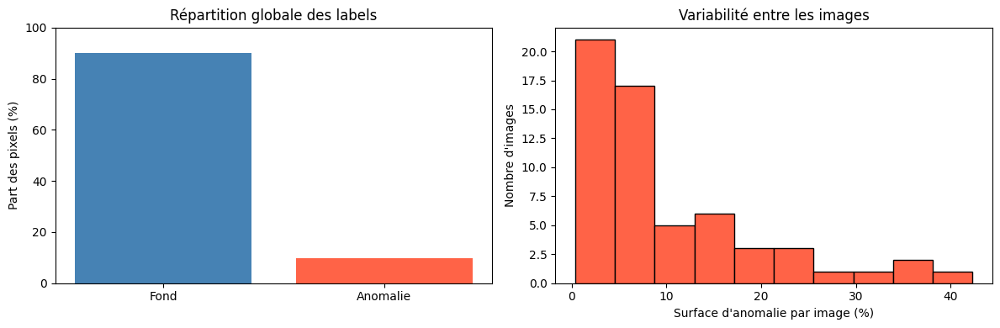

Accuracy théorique en prédisant toujours le fond : 90.15%


In [ ]:
HIST_BINS = 10

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    ["Fond", "Anomalie"],
    [
        100 * (1 - global_anomaly_fraction),
        100 * global_anomaly_fraction,
    ],
    color=["steelblue", "tomato"],
)
axes[0].set_ylabel("Part des pixels (%)")
axes[0].set_ylim(0, 100)
axes[0].set_title("Répartition globale des labels")

axes[1].hist(
    anomaly_fractions * 100,
    bins=HIST_BINS,
    color="tomato",
    edgecolor="black",
)
axes[1].set_xlabel("Surface d'anomalie par image (%)")
axes[1].set_ylabel("Nombre d'images")
axes[1].set_title("Variabilité entre les images")

plt.tight_layout()
plt.show()

background_only_accuracy = 1 - global_anomaly_fraction

print(
    "Accuracy théorique en prédisant toujours le fond : "
    f"{background_only_accuracy:.2%}"
)

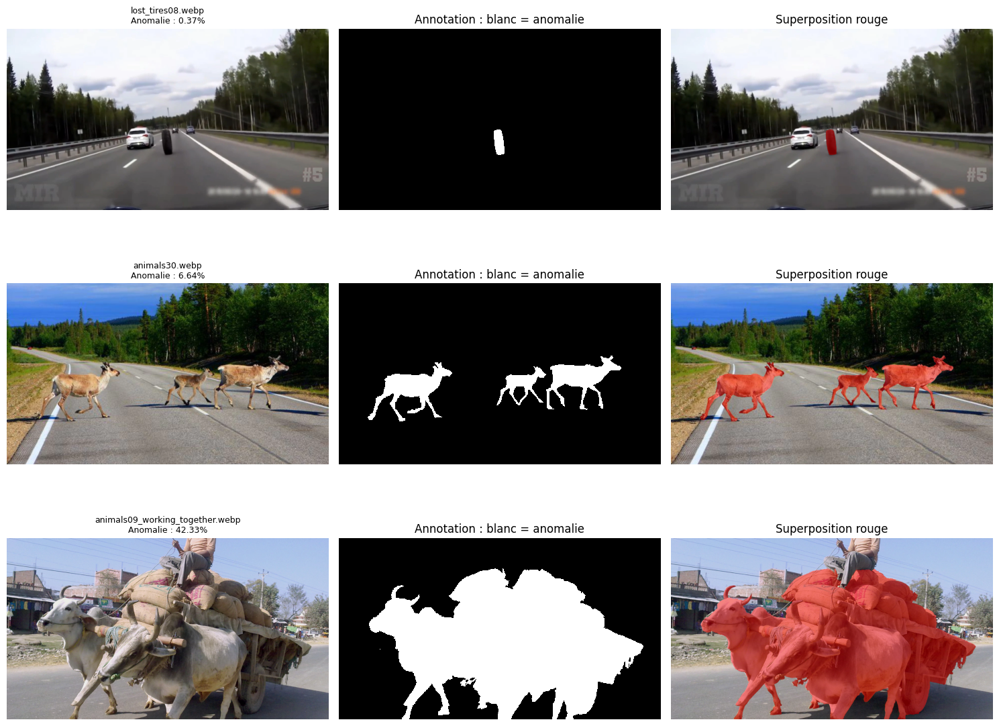

In [ ]:
OVERLAY_ALPHA = 0.45


def show_annotations(records):
    fig, axes = plt.subplots(
        len(records), 3,
        figsize=(15, 4 * len(records)),
        squeeze=False,
    )

    for row, record in enumerate(records):
        with Image.open(record["image_path"]) as image:
            image_array = np.array(image.convert("RGB"))

        with Image.open(record["mask_path"]) as mask:
            anomaly_mask = np.array(mask) == 2

        overlay = image_array.copy()
        overlay[anomaly_mask] = (
            (1 - OVERLAY_ALPHA) * image_array[anomaly_mask]
            + OVERLAY_ALPHA * np.array([255, 0, 0])
        ).astype(np.uint8)

        axes[row, 0].imshow(image_array)
        axes[row, 0].set_title(
            f"{record['name']}\n"
            f"Anomalie : {record['anomaly_fraction']:.2%}",
            fontsize=9,
        )

        axes[row, 1].imshow(
            anomaly_mask,
            cmap="gray",
            vmin=0,
            vmax=1,
            interpolation="nearest",
        )
        axes[row, 1].set_title("Annotation : blanc = anomalie")

        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title("Superposition rouge")

        for axis in axes[row]:
            axis.axis("off")

    plt.tight_layout()
    plt.show()


sorted_records = sorted(
    exploration_records,
    key=lambda record: record["anomaly_fraction"],
)

selected_records = [
    sorted_records[0],
    sorted_records[len(sorted_records) // 2],
    sorted_records[-1],
]

show_annotations(selected_records)

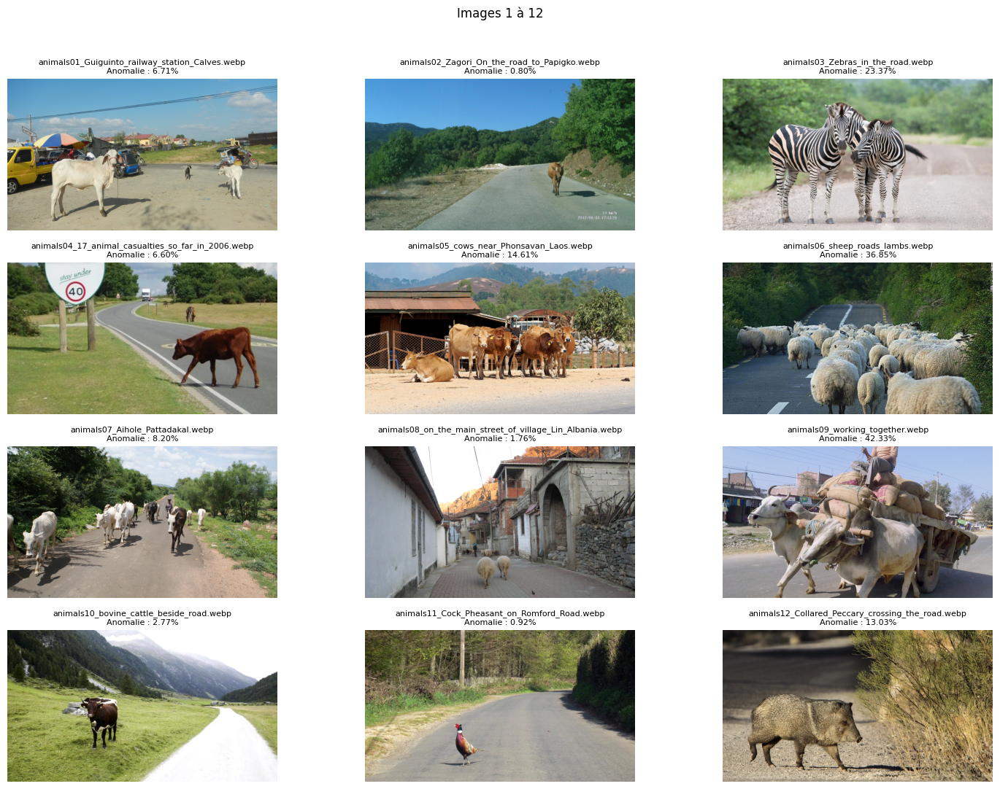

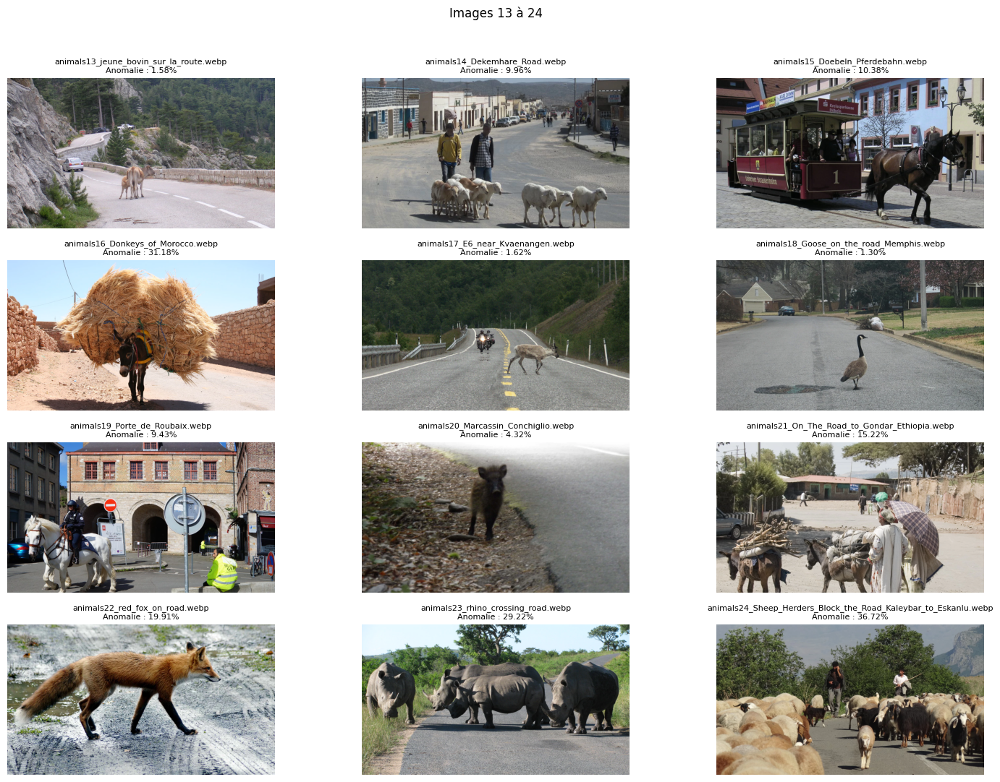

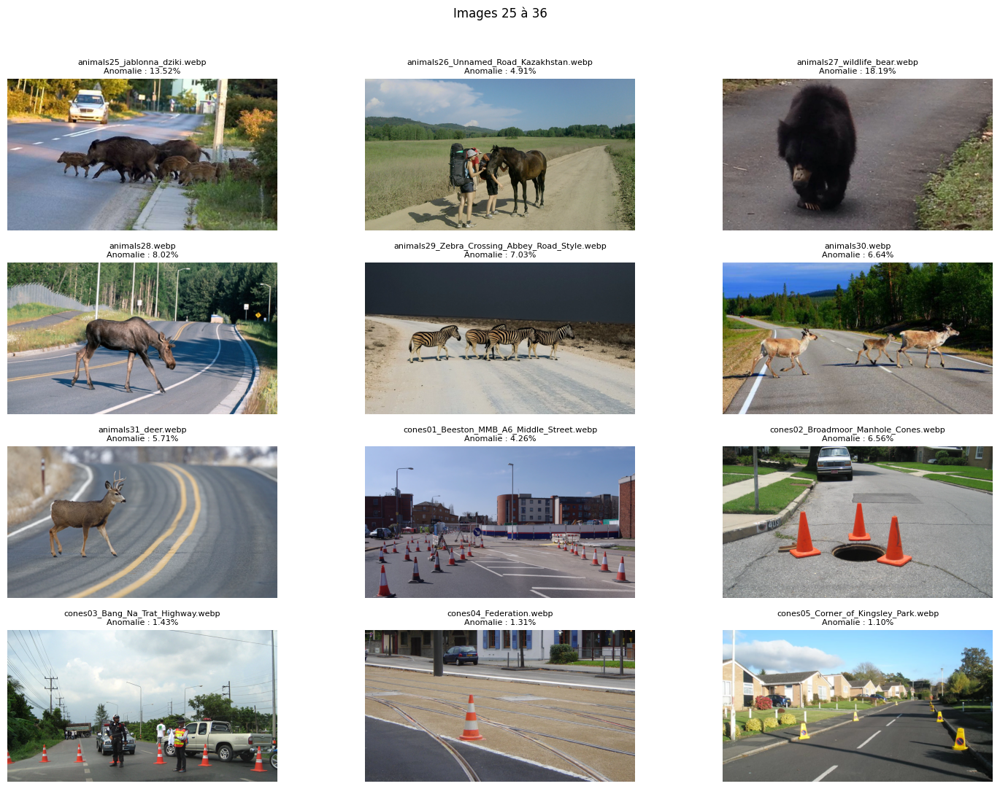

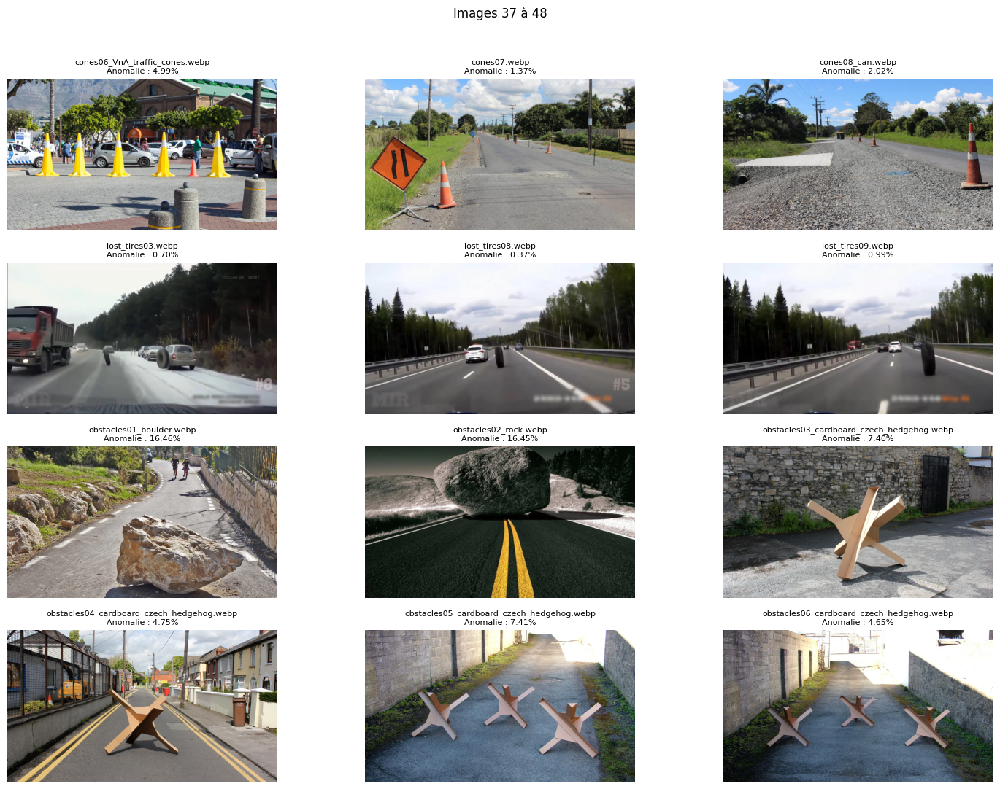

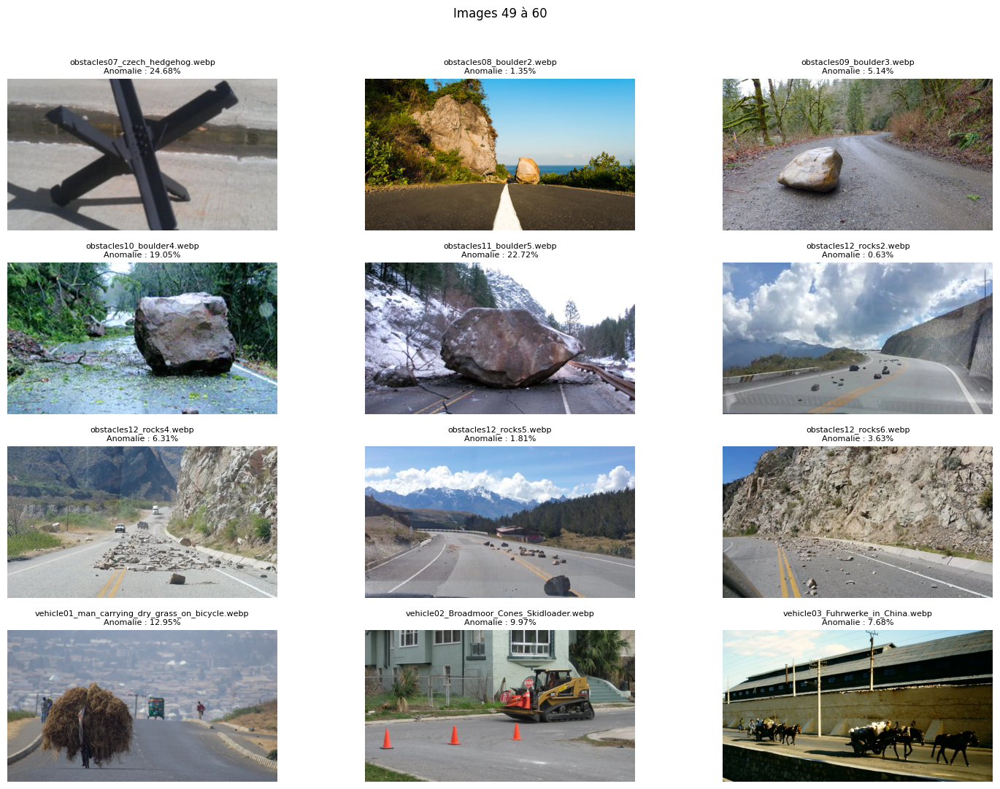

In [ ]:
IMAGES_PER_PAGE = 12
N_COLUMNS = 3
N_ROWS = 4

for start in range(0, len(exploration_records), IMAGES_PER_PAGE):
    page_records = exploration_records[
        start:start + IMAGES_PER_PAGE
    ]

    fig, axes = plt.subplots(
        N_ROWS, N_COLUMNS,
        figsize=(15, 11),
    )
    axes = axes.ravel()

    for axis, record in zip(axes, page_records):
        with Image.open(record["image_path"]) as image:
            axis.imshow(image)

        axis.set_title(
            f"{record['name']}\n"
            f"Anomalie : {record['anomaly_fraction']:.2%}",
            fontsize=8,
        )
        axis.axis("off")

    for axis in axes[len(page_records):]:
        axis.axis("off")

    fig.suptitle(
        f"Images {start + 1} à {start + len(page_records)}"
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

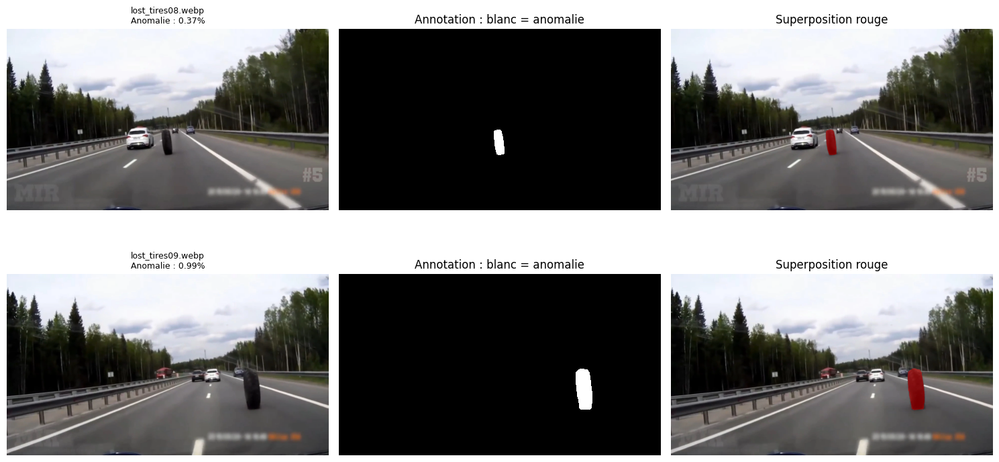

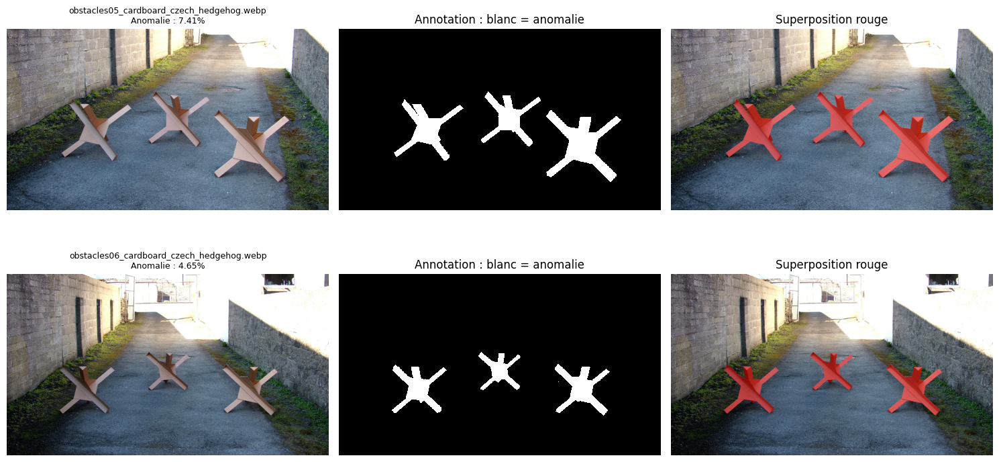

In [ ]:
candidate_pairs = [
    ("lost_tires08.webp", "lost_tires09.webp"),
    (
        "obstacles05_cardboard_czech_hedgehog.webp",
        "obstacles06_cardboard_czech_hedgehog.webp",
    ),
]

exploration_by_name = {
    record["name"]: record
    for record in exploration_records
}

for pair in candidate_pairs:
    missing_names = [
        name for name in pair
        if name not in exploration_by_name
    ]

    if missing_names:
        raise ValueError(f"Images absentes : {missing_names}")

    show_annotations([
        exploration_by_name[name]
        for name in pair
    ])

4. Grouped Data Splitting / Partitionnement par groupes 🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑

In [ ]:
import random
import json
from pathlib import Path
from collections import defaultdict

required_variables = [
    "dataset_records", "exploration_records", "PROJECT_DIR", "SEED"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Exécute les étapes précédentes : {missing_variables}"
    )

TRAIN_GROUP_FRACTION = 0.70
VAL_GROUP_FRACTION = 0.15

if not (
    0 < TRAIN_GROUP_FRACTION < 1
    and 0 < VAL_GROUP_FRACTION < 1
    and TRAIN_GROUP_FRACTION + VAL_GROUP_FRACTION < 1
):
    raise ValueError("Proportions de partitionnement invalides.")

print("Graine :", SEED)
print("Proportion visée des groupes :")
print("- Train :", TRAIN_GROUP_FRACTION)
print("- Validation :", VAL_GROUP_FRACTION)
print("- Test :", 1 - TRAIN_GROUP_FRACTION - VAL_GROUP_FRACTION)

Graine : 42
Proportion visée des groupes :
- Train : 0.7
- Validation : 0.15
- Test : 0.15000000000000005


In [ ]:
scene_groups = {
    "lost_tires": [
        "lost_tires03.webp",
        "lost_tires08.webp",
        "lost_tires09.webp",
    ],
    "cardboard_obstacles": [
        "obstacles03_cardboard_czech_hedgehog.webp",
        "obstacles04_cardboard_czech_hedgehog.webp",
        "obstacles05_cardboard_czech_hedgehog.webp",
        "obstacles06_cardboard_czech_hedgehog.webp",
        "obstacles07_czech_hedgehog.webp",
    ],
    "rocks_series": [
        "obstacles12_rocks2.webp",
        "obstacles12_rocks4.webp",
        "obstacles12_rocks5.webp",
        "obstacles12_rocks6.webp",
    ],
    "broadmoor": [
        "cones02_Broadmoor_Manhole_Cones.webp",
        "vehicle02_Broadmoor_Cones_Skidloader.webp",
    ],
}

In [ ]:
records_by_name = {
    record["name"]: record
    for record in dataset_records
}

if len(records_by_name) != len(dataset_records):
    raise ValueError("Des noms sont répétés dans l'inventaire.")

group_by_name = {}

for group_id, names in scene_groups.items():
    for name in names:
        if name not in records_by_name:
            raise ValueError(f"Image absente : {name}")

        if name in group_by_name:
            raise ValueError(f"Image présente dans plusieurs groupes : {name}")

        group_by_name[name] = group_id

for name in sorted(records_by_name):
    if name not in group_by_name:
        group_by_name[name] = f"single::{name}"

group_members = defaultdict(list)

for name, group_id in group_by_name.items():
    group_members[group_id].append(name)

print("Nombre d'images :", len(records_by_name))
print("Nombre de groupes :", len(group_members))

print("\nGroupes de plusieurs images :")
for group_id, names in sorted(group_members.items()):
    if len(names) > 1:
        print(f"- {group_id} : {len(names)} images")

Nombre d'images : 60
Nombre de groupes : 50

Groupes de plusieurs images :
- broadmoor : 2 images
- cardboard_obstacles : 5 images
- lost_tires : 3 images
- rocks_series : 4 images


In [ ]:
group_ids = sorted(group_members)

random.Random(SEED).shuffle(group_ids)

n_groups = len(group_ids)
n_train_groups = int(TRAIN_GROUP_FRACTION * n_groups)
n_val_groups = int(VAL_GROUP_FRACTION * n_groups)

split_group_ids = {
    "train": group_ids[:n_train_groups],
    "validation": group_ids[
        n_train_groups:n_train_groups + n_val_groups
    ],
    "test": group_ids[n_train_groups + n_val_groups:],
}

split_names = {
    split: sorted(
        name
        for group_id in assigned_groups
        for name in group_members[group_id]
    )
    for split, assigned_groups in split_group_ids.items()
}

train_records = [
    records_by_name[name] for name in split_names["train"]
]
val_records = [
    records_by_name[name] for name in split_names["validation"]
]
test_records = [
    records_by_name[name] for name in split_names["test"]
]

for split, names in split_names.items():
    print(
        f"{split} : {len(names)} images "
        f"({len(names) / len(dataset_records):.1%}), "
        f"{len(split_group_ids[split])} groupes"
    )

train : 39 images (65.0%), 35 groupes
validation : 9 images (15.0%), 7 groupes
test : 12 images (20.0%), 8 groupes


In [ ]:
name_sets = {
    split: set(names)
    for split, names in split_names.items()
}

if any(not names for names in name_sets.values()):
    raise ValueError("Une partition est vide.")

for first, second in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    overlap = name_sets[first] & name_sets[second]

    if overlap:
        raise ValueError(
            f"Images communes à {first} et {second} : {overlap}"
        )

all_assigned_names = set().union(*name_sets.values())

if all_assigned_names != set(records_by_name):
    raise ValueError("Des images sont manquantes ou inattendues.")

group_partitions = defaultdict(set)

for split, names in split_names.items():
    for name in names:
        group_partitions[group_by_name[name]].add(split)

crossed_groups = {
    group_id: sorted(partitions)
    for group_id, partitions in group_partitions.items()
    if len(partitions) > 1
}

if crossed_groups:
    raise ValueError(f"Groupes présents dans plusieurs partitions : {crossed_groups}")

print("Contrôles réussis :")
print("- Trois partitions non vides.")
print("- Chaque image apparaît dans une seule partition.")
print("- Toutes les images sont affectées.")
print("- Aucun groupe déclaré ne traverse les partitions.")

Contrôles réussis :
- Trois partitions non vides.
- Chaque image apparaît dans une seule partition.
- Toutes les images sont affectées.
- Aucun groupe déclaré ne traverse les partitions.


In [ ]:
from collections import Counter

filename_prefixes = [
    "animals", "cones", "lost_tires", "obstacles", "vehicle"
]

def filename_family(name):
    for prefix in filename_prefixes:
        if name.startswith(prefix):
            return prefix
    return "other"

for split, names in split_names.items():
    counts = Counter(filename_family(name) for name in names)

    print(f"\n{split.upper()} — {len(names)} images")
    for family in filename_prefixes + ["other"]:
        if counts[family]:
            print(f"- {family} : {counts[family]}")


TRAIN — 39 images
- animals : 22
- cones : 6
- obstacles : 9
- vehicle : 2

VALIDATION — 9 images
- animals : 3
- cones : 1
- lost_tires : 3
- obstacles : 1
- vehicle : 1

TEST — 12 images
- animals : 6
- cones : 1
- obstacles : 5


In [ ]:
split_payload = {
    "status": "provisional_pending_group_review",
    "seed": SEED,
    "method": "random_split_of_declared_scene_groups",
    "train_group_fraction": TRAIN_GROUP_FRACTION,
    "validation_group_fraction": VAL_GROUP_FRACTION,
    "scene_groups": scene_groups,
    "group_by_name": group_by_name,
    "splits": split_names,
}

split_dir = Path(PROJECT_DIR) / "outputs" / "partitioning"
split_dir.mkdir(parents=True, exist_ok=True)

split_path = split_dir / "grouped_splits_seed42_provisional.json"

if split_path.exists():
    existing_payload = json.loads(
        split_path.read_text(encoding="utf-8")
    )

    if existing_payload != split_payload:
        raise FileExistsError(
            "Une proposition différente existe déjà. "
            "Comparons les deux avant de la remplacer."
        )

    print("Une proposition identique est déjà enregistrée.")
else:
    split_path.write_text(
        json.dumps(split_payload, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    print("Proposition enregistrée.")

print("Emplacement :", split_path)
print("Statut :", split_payload["status"])

Une proposition identique est déjà enregistrée.
Emplacement : /content/project-deeplearning/outputs/partitioning/grouped_splits_seed42_provisional.json
Statut : provisional_pending_group_review


Étape 5 — Data Preprocessing / Prétraitement  🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

required_variables = [
    "train_records", "val_records", "test_records",
    "exploration_records", "SEED",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Exécute les étapes précédentes : {missing_variables}"
    )

if not train_records or not val_records or not test_records:
    raise ValueError("Les trois partitions doivent être non vides.")

IMG_HEIGHT = 360
IMG_WIDTH = 640
BATCH_SIZE = 4

tf.keras.utils.set_random_seed(SEED)

print("Entrée prévue :", (IMG_HEIGHT, IMG_WIDTH, 3))
print("Cible prévue :", (IMG_HEIGHT, IMG_WIDTH, 1))
print("Taille maximale des lots :", BATCH_SIZE)

Entrée prévue : (360, 640, 3)
Cible prévue : (360, 640, 1)
Taille maximale des lots : 4


In [ ]:
def load_image_mask(record):
    with Image.open(record["image_path"]) as image:
        image = image.convert("RGB")

        resized_image = image.resize(
            (IMG_WIDTH, IMG_HEIGHT),
            resample=Image.Resampling.BILINEAR,
        )

        image_array = (
            np.asarray(resized_image, dtype=np.float32) / 255.0
        )

    with Image.open(record["mask_path"]) as mask:
        native_mask = np.asarray(mask)

        if native_mask.ndim != 2:
            raise ValueError(f"Masque invalide : {record['name']}")

        if not set(np.unique(native_mask)).issubset({0, 2}):
            raise ValueError(f"Labels inattendus : {record['name']}")

        resized_mask = mask.resize(
            (IMG_WIDTH, IMG_HEIGHT),
            resample=Image.Resampling.NEAREST,
        )

        mask_array = (
            np.asarray(resized_mask) == 2
        ).astype(np.float32)

    mask_array = mask_array[..., np.newaxis]

    return image_array, mask_array

Exemple : obstacles12_rocks2.webp
Image préparée : (360, 640, 3) float32
Masque préparé : (360, 640, 1) float32
Labels préparés : [0. 1.]
Surface d'anomalie originale : 0.6280%
Surface d'anomalie préparée : 0.6293%


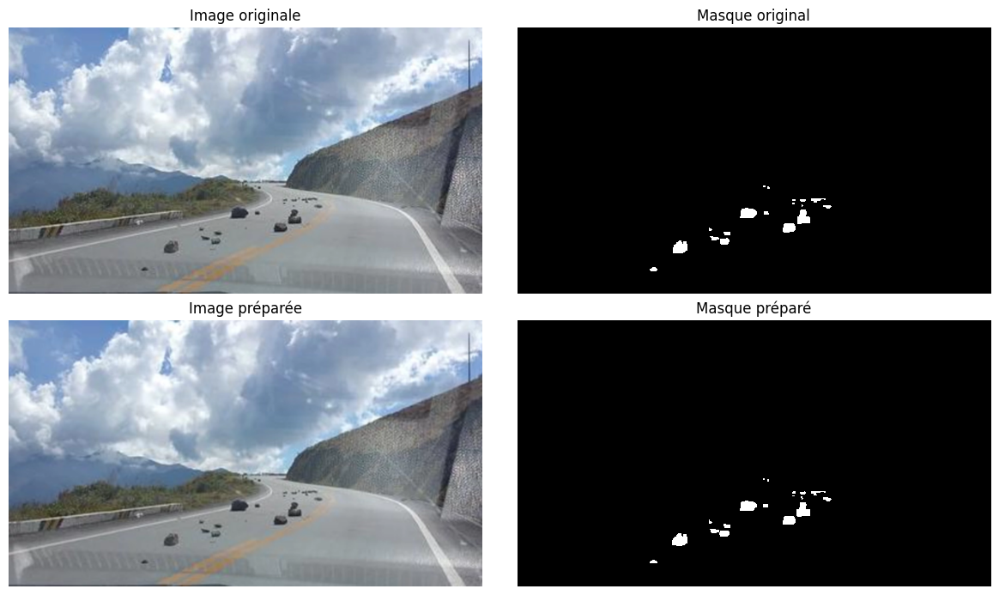

In [ ]:
exploration_by_name = {
    record["name"]: record
    for record in exploration_records
}

sample_record = min(
    train_records,
    key=lambda record: exploration_by_name[
        record["name"]
    ]["anomaly_fraction"],
)

sample_image, sample_mask = load_image_mask(sample_record)

with Image.open(sample_record["image_path"]) as image:
    native_image = np.array(image.convert("RGB"))

with Image.open(sample_record["mask_path"]) as mask:
    native_binary_mask = np.array(mask) == 2

print("Exemple :", sample_record["name"])
print("Image préparée :", sample_image.shape, sample_image.dtype)
print("Masque préparé :", sample_mask.shape, sample_mask.dtype)
print("Labels préparés :", np.unique(sample_mask))

print(f"Surface d'anomalie originale : {native_binary_mask.mean():.4%}")
print(f"Surface d'anomalie préparée : {sample_mask.mean():.4%}")

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

axes[0, 0].imshow(native_image)
axes[0, 0].set_title("Image originale")

axes[0, 1].imshow(
    native_binary_mask, cmap="gray",
    vmin=0, vmax=1, interpolation="nearest",
)
axes[0, 1].set_title("Masque original")

axes[1, 0].imshow(sample_image)
axes[1, 0].set_title("Image préparée")

axes[1, 1].imshow(
    sample_mask[..., 0], cmap="gray",
    vmin=0, vmax=1, interpolation="nearest",
)
axes[1, 1].set_title("Masque préparé")

for axis in axes.ravel():
    axis.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
vanished_anomalies = []

for record in train_records:
    with Image.open(record["mask_path"]) as mask:
        has_native_anomaly = bool(np.any(np.array(mask) == 2))

    _, prepared_mask = load_image_mask(record)
    has_prepared_anomaly = bool(np.any(prepared_mask == 1))

    if has_native_anomaly and not has_prepared_anomaly:
        vanished_anomalies.append(record["name"])

print("Annotations devenues entièrement vides :", vanished_anomalies)

if vanished_anomalies:
    raise ValueError(
        "Le redimensionnement supprime entièrement certaines annotations. "
        "Nous devons revoir la résolution."
    )

Annotations devenues entièrement vides : []


In [ ]:
def make_dataset(records, training=False):
    records = tuple(records)

    def generate_examples():
        for record in records:
            yield load_image_mask(record)

    dataset = tf.data.Dataset.from_generator(
        generate_examples,
        output_signature=(
            tf.TensorSpec(
                shape=(IMG_HEIGHT, IMG_WIDTH, 3),
                dtype=tf.float32,
            ),
            tf.TensorSpec(
                shape=(IMG_HEIGHT, IMG_WIDTH, 1),
                dtype=tf.float32,
            ),
        ),
    )

    dataset = dataset.apply(
        tf.data.experimental.assert_cardinality(len(records))
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(records),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False,
    )

    return dataset.prefetch(1)


train_ds = make_dataset(train_records, training=True)
val_ds = make_dataset(val_records)
test_ds = make_dataset(test_records)

print("Chaînes de chargement créées.")

Chaînes de chargement créées.


In [ ]:
batch_images, batch_masks = next(iter(train_ds))

tf.debugging.assert_shapes([
    (batch_images, ("B", IMG_HEIGHT, IMG_WIDTH, 3)),
    (batch_masks, ("B", IMG_HEIGHT, IMG_WIDTH, 1)),
])

tf.debugging.assert_all_finite(
    batch_images, "Valeurs non finies dans les images"
)
tf.debugging.assert_all_finite(
    batch_masks, "Valeurs non finies dans les masques"
)

tf.debugging.assert_greater_equal(batch_images, 0.0)
tf.debugging.assert_less_equal(batch_images, 1.0)

tf.debugging.assert_equal(
    tf.reduce_all(
        tf.logical_or(batch_masks == 0.0, batch_masks == 1.0)
    ),
    True,
)

print("Lot d'images :", batch_images.shape)
print("Lot de masques :", batch_masks.shape)

print("Nombre de lots train :", len(train_ds))
print("Nombre de lots validation :", len(val_ds))
print("Nombre de lots test :", len(test_ds))

print("Contrôles du lot d'entraînement réussis.")

Lot d'images : (4, 360, 640, 3)
Lot de masques : (4, 360, 640, 1)
Nombre de lots train : 10
Nombre de lots validation : 3
Nombre de lots test : 3
Contrôles du lot d'entraînement réussis.


6. Baseline Architecture / Architecture du modèle de référence 🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers

required_variables = [
    "IMG_HEIGHT", "IMG_WIDTH", "train_ds", "SEED"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Exécute les étapes précédentes : {missing_variables}"
    )

BASE_FILTERS = 16
KERNEL_SIZE = 3
POOL_SIZE = 2

reduction_factor = POOL_SIZE ** 2

if (
    IMG_HEIGHT % reduction_factor != 0
    or IMG_WIDTH % reduction_factor != 0
):
    raise ValueError(
        f"La hauteur et la largeur doivent être divisibles par "
        f"{reduction_factor} pour cette architecture."
    )

tf.keras.utils.set_random_seed(SEED)

print("Entrée :", (IMG_HEIGHT, IMG_WIDTH, 3))
print(
    "Résolution après deux réductions :",
    (IMG_HEIGHT // reduction_factor, IMG_WIDTH // reduction_factor),
)

Entrée : (360, 640, 3)
Résolution après deux réductions : (90, 160)


In [ ]:
baseline_model = tf.keras.Sequential(
    [
        layers.Input(
            shape=(IMG_HEIGHT, IMG_WIDTH, 3),
            name="rgb_image",
        ),

        # Encodeur : extraire des caractéristiques et réduire la résolution.
        layers.Conv2D(
            BASE_FILTERS,
            KERNEL_SIZE,
            padding="same",
            activation="relu",
            kernel_initializer="he_normal",
            name="encoder_conv_1",
        ),
        layers.MaxPooling2D(
            pool_size=POOL_SIZE,
            name="encoder_pool_1",
        ),

        layers.Conv2D(
            BASE_FILTERS * 2,
            KERNEL_SIZE,
            padding="same",
            activation="relu",
            kernel_initializer="he_normal",
            name="encoder_conv_2",
        ),
        layers.MaxPooling2D(
            pool_size=POOL_SIZE,
            name="encoder_pool_2",
        ),

        # Représentation à résolution réduite.
        layers.Conv2D(
            BASE_FILTERS * 4,
            KERNEL_SIZE,
            padding="same",
            activation="relu",
            kernel_initializer="he_normal",
            name="bottleneck",
        ),

        # Décodeur : agrandir les cartes puis les transformer.
        layers.UpSampling2D(
            size=POOL_SIZE,
            interpolation="nearest",
            name="decoder_upsampling_1",
        ),
        layers.Conv2D(
            BASE_FILTERS * 2,
            KERNEL_SIZE,
            padding="same",
            activation="relu",
            kernel_initializer="he_normal",
            name="decoder_conv_1",
        ),

        layers.UpSampling2D(
            size=POOL_SIZE,
            interpolation="nearest",
            name="decoder_upsampling_2",
        ),
        layers.Conv2D(
            BASE_FILTERS,
            KERNEL_SIZE,
            padding="same",
            activation="relu",
            kernel_initializer="he_normal",
            name="decoder_conv_2",
        ),

        # Un score d'anomalie pour chaque pixel.
        layers.Conv2D(
            filters=1,
            kernel_size=1,
            padding="same",
            activation="sigmoid",
            name="anomaly_probability",
        ),
    ],
    name="baseline_segmentation_cnn",
)

In [ ]:
baseline_model.summary()

print("\nForme d'entrée :", baseline_model.input_shape)
print("Forme de sortie :", baseline_model.output_shape)
print("Nombre de paramètres :", baseline_model.count_params())

Model: "baseline_segmentation_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_conv_1 (Conv2D)         │ (None, 360, 640, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_pool_1 (MaxPooling2D)   │ (None, 180, 320, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_conv_2 (Conv2D)         │ (None, 180, 320, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_pool_2 (MaxPooling2D)   │ (None, 90, 160, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Conv2D)             │ (None, 90, 160, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_upsampling_1            │ (None, 180, 320, 64)   │             0 │
│ (UpSampling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_conv_1 (Conv2D)         │ (None, 180, 320, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_upsampling_2            │ (None, 360, 640, 32)   │             0 │
│ (UpSampling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_conv_2 (Conv2D)         │ (None, 360, 640, 16)   │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ anomaly_probability (Conv2D)    │ (None, 360, 640, 1)    │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,689 (182.38 KB)

 Trainable params: 46,689 (182.38 KB)

 Non-trainable params: 0 (0.00 B)


Forme d'entrée : (None, 360, 640, 3)
Forme de sortie : (None, 360, 640, 1)
Nombre de paramètres : 46689


In [ ]:
architecture_images, architecture_masks = next(iter(train_ds))

# Une seule image suffit pour vérifier les dimensions.
architecture_images = architecture_images[:1]
architecture_masks = architecture_masks[:1]

architecture_outputs = baseline_model(
    architecture_images,
    training=False,
)

tf.debugging.assert_equal(
    tf.shape(architecture_outputs),
    tf.shape(architecture_masks),
)

tf.debugging.assert_all_finite(
    architecture_outputs,
    "La sortie contient des valeurs non finies.",
)

tf.debugging.assert_greater_equal(architecture_outputs, 0.0)
tf.debugging.assert_less_equal(architecture_outputs, 1.0)

print("Entrée :", architecture_images.shape)
print("Cible :", architecture_masks.shape)
print("Sortie :", architecture_outputs.shape)

print(
    "Intervalle des scores :",
    float(tf.reduce_min(architecture_outputs).numpy()),
    float(tf.reduce_max(architecture_outputs).numpy()),
)

print("Contrôles structurels réussis.")

Entrée : (1, 360, 640, 3)
Cible : (1, 360, 640, 1)
Sortie : (1, 360, 640, 1)
Intervalle des scores : 0.16008204221725464 0.7900059819221497
Contrôles structurels réussis.


Étape 7 — Baseline Training / Entraînement du modèle de référence 🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑

In [ ]:
import json
import time
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

required_variables = [
    "baseline_model", "train_ds", "val_ds",
    "train_records", "val_records", "test_records",
    "dataset_records", "group_by_name",
    "PROJECT_DIR", "IMG_HEIGHT", "IMG_WIDTH",
    "BATCH_SIZE", "SEED",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Exécute les étapes précédentes : {missing_variables}"
    )

partitions = {
    "train": train_records,
    "validation": val_records,
    "test": test_records,
}

partition_names = {
    split: {record["name"] for record in records}
    for split, records in partitions.items()
}

partition_groups = {
    split: {group_by_name[name] for name in names}
    for split, names in partition_names.items()
}

for split, records in partitions.items():
    if not records:
        raise ValueError(f"Partition vide : {split}")

    if len(partition_names[split]) != len(records):
        raise ValueError(f"Noms répétés dans {split}")

for first, second in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    if partition_names[first] & partition_names[second]:
        raise ValueError(f"Images communes : {first} / {second}")

    if partition_groups[first] & partition_groups[second]:
        raise ValueError(f"Groupes communs : {first} / {second}")

if set().union(*partition_names.values()) != {
    record["name"] for record in dataset_records
}:
    raise ValueError("Les partitions ne couvrent pas exactement le dataset.")

for split, records in partitions.items():
    print(f"{split} : {len(records)} images")

print("Contrôles structurels des partitions réussis.")

train : 39 images
validation : 9 images
test : 12 images
Contrôles structurels des partitions réussis.


In [ ]:
LEARNING_RATE = 1e-3
MAX_EPOCHS = 50
PATIENCE = 7
MONITOR_THRESHOLD = 0.5

existing_optimizer = getattr(baseline_model, "optimizer", None)

if (
    existing_optimizer is not None
    and int(existing_optimizer.iterations.numpy()) > 0
):
    raise RuntimeError(
        "Ce modèle a déjà été entraîné. "
        "Pour une nouvelle expérience depuis zéro, reconstruis-le à l'étape 6."
    )

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=tf.keras.losses.BinaryCrossentropy(
        from_logits=False
    ),
    metrics=[
        tf.keras.metrics.Precision(
            name="precision",
            thresholds=MONITOR_THRESHOLD,
        ),
        tf.keras.metrics.Recall(
            name="recall",
            thresholds=MONITOR_THRESHOLD,
        ),
    ],
)

print("Configuration de l'apprentissage préparée.")

Configuration de l'apprentissage préparée.


In [ ]:
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
baseline_run_dir = Path(PROJECT_DIR) / "outputs" / "baseline" / run_id
baseline_run_dir.mkdir(parents=True, exist_ok=False)

checkpoint_path = baseline_run_dir / "best_model.keras"

run_config = {
    "model_name": baseline_model.name,
    "seed": SEED,
    "image_height": IMG_HEIGHT,
    "image_width": IMG_WIDTH,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "loss": "binary_crossentropy",
    "monitor": "val_loss",
    "monitor_threshold": MONITOR_THRESHOLD,
    "tensorflow_version": tf.__version__,
    "gpu_devices": [
        device.name
        for device in tf.config.list_physical_devices("GPU")
    ],
    "splits": {
        split: sorted(names)
        for split, names in partition_names.items()
    },
    "group_by_name": group_by_name,
}

(baseline_run_dir / "run_config.json").write_text(
    json.dumps(run_config, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

training_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        min_delta=0.0,
        patience=PATIENCE,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.CSVLogger(
        str(baseline_run_dir / "training_log.csv")
    ),
    tf.keras.callbacks.TerminateOnNaN(),
]

print("Dossier de l'expérience :", baseline_run_dir)

Dossier de l'expérience : /content/project-deeplearning/outputs/baseline/20261030T170041_702392Z


In [ ]:
if int(baseline_model.optimizer.iterations.numpy()) > 0:
    raise RuntimeError(
        "Ce modèle a déjà effectué des mises à jour. "
        "Ne relance pas cette cellule comme une nouvelle expérience."
    )

training_start = time.perf_counter()

baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS,
    callbacks=training_callbacks,
    verbose=1,
)

training_duration_seconds = (
    time.perf_counter() - training_start
)

print(
    f"Durée de l'entraînement : "
    f"{training_duration_seconds / 60:.2f} minutes"
)

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - loss: 0.4294 - precision: 0.0976 - recall: 0.0576
Epoch 1: val_loss improved from None to 0.35836, saving model to /content/project-deeplearning/outputs/baseline/20261030T170041_702392Z/best_model.keras

Epoch 1: finished saving model to /content/project-deeplearning/outputs/baseline/20261030T170041_702392Z/best_model.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 531ms/step - loss: 0.4088 - precision: 0.0974 - recall: 0.0129 - val_loss: 0.3584 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 0.3182 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 2: val_loss improved from 0.35836 to 0.31350, saving model to /content/project-deeplearning/outputs/baseline/20261030T170041_702392Z/best_model.keras

Epoch 2: finished saving model to /content/project-deeplearning/outputs/baseline/20261030T170041_702392Z/best_model.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 145ms/step - loss: 0.3436 - precis

In [ ]:
history_values = {
    name: [float(value) for value in values]
    for name, values in baseline_history.history.items()
}

(baseline_run_dir / "history.json").write_text(
    json.dumps(history_values, indent=2),
    encoding="utf-8",
)

validation_losses = np.array(history_values["val_loss"])

if not np.all(np.isfinite(validation_losses)):
    raise ValueError(
        "Des pertes de validation ne sont pas finies. "
        "Il faut examiner les journaux avant de poursuivre."
    )

if not checkpoint_path.is_file():
    raise FileNotFoundError("Aucun meilleur modèle n'a été sauvegardé.")

best_epoch = int(np.argmin(validation_losses)) + 1

baseline_model = tf.keras.models.load_model(checkpoint_path)

training_summary = {
    "epochs_completed": len(history_values["loss"]),
    "best_epoch": best_epoch,
    "best_validation_loss": float(validation_losses.min()),
    "training_duration_seconds": training_duration_seconds,
}

(baseline_run_dir / "training_summary.json").write_text(
    json.dumps(training_summary, indent=2),
    encoding="utf-8",
)

print("Époques effectuées :", training_summary["epochs_completed"])
print("Meilleure époque :", training_summary["best_epoch"])
print("Meilleure val_loss :", training_summary["best_validation_loss"])
print("Meilleur modèle rechargé :", checkpoint_path)

Époques effectuées : 20
Meilleure époque : 13
Meilleure val_loss : 0.2171754240989685
Meilleur modèle rechargé : /content/project-deeplearning/outputs/baseline/20261030T170041_702392Z/best_model.keras


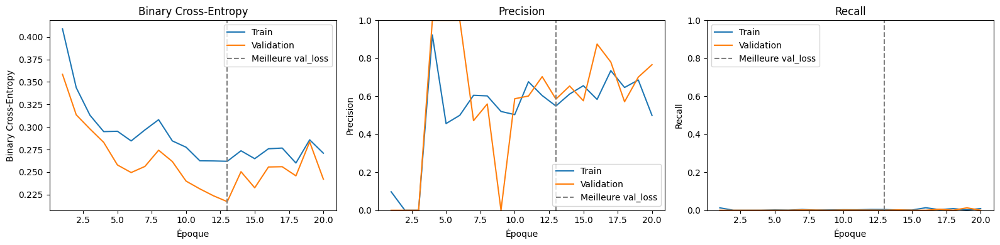

In [ ]:
epoch_numbers = np.arange(1, len(history_values["loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for axis, metric, title in zip(
    axes,
    ["loss", "precision", "recall"],
    ["Binary Cross-Entropy", "Precision", "Recall"],
):
    axis.plot(
        epoch_numbers,
        history_values[metric],
        label="Train",
    )
    axis.plot(
        epoch_numbers,
        history_values[f"val_{metric}"],
        label="Validation",
    )

    axis.axvline(
        best_epoch,
        color="gray",
        linestyle="--",
        label="Meilleure val_loss",
    )

    axis.set_xlabel("Époque")
    axis.set_ylabel(title)
    axis.set_title(title)
    axis.legend()

    if metric != "loss":
        axis.set_ylim(0, 1)

plt.tight_layout()
plt.savefig(
    baseline_run_dir / "learning_curves.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [ ]:
import shutil
from google.colab import files

archive_path = shutil.make_archive(
    base_name=str(baseline_run_dir),
    format="zip",
    root_dir=str(baseline_run_dir),
)

files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

8. Transfer Learning Model / Modèle avec transfert d’apprentissage 🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers

required_variables = [
    "IMG_HEIGHT", "IMG_WIDTH", "train_ds", "SEED"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Exécute les étapes précédentes : {missing_variables}"
    )

DECODER_FILTERS = (128, 64, 32, 16)
FINAL_FILTERS = 8

ENCODER_STRIDE = 32

PAD_HEIGHT = (-IMG_HEIGHT) % ENCODER_STRIDE
PAD_WIDTH = (-IMG_WIDTH) % ENCODER_STRIDE

PADDED_HEIGHT = IMG_HEIGHT + PAD_HEIGHT
PADDED_WIDTH = IMG_WIDTH + PAD_WIDTH

tf.keras.utils.set_random_seed(SEED)

print("Entrée conservée :", (IMG_HEIGHT, IMG_WIDTH, 3))
print("Ajout en bas :", PAD_HEIGHT, "pixels")
print("Ajout à droite :", PAD_WIDTH, "pixels")
print("Dimensions internes :", (PADDED_HEIGHT, PADDED_WIDTH))

Entrée conservée : (360, 640, 3)
Ajout en bas : 24 pixels
Ajout à droite : 0 pixels
Dimensions internes : (384, 640)


In [ ]:
transfer_backbone = tf.keras.applications.MobileNetV2(
    input_shape=(PADDED_HEIGHT, PADDED_WIDTH, 3),
    include_top=False,
    weights="imagenet",
    alpha=1.0,
)

feature_layer_names = [
    "block_1_expand_relu",
    "block_3_expand_relu",
    "block_6_expand_relu",
    "block_13_expand_relu",
    "block_16_project",
]

transfer_encoder = tf.keras.Model(
    inputs=transfer_backbone.input,
    outputs=[
        transfer_backbone.get_layer(name).output
        for name in feature_layer_names
    ],
    name="mobilenetv2_encoder",
)

transfer_encoder.trainable = False

for name, output in zip(
    feature_layer_names,
    transfer_encoder.outputs,
):
    print(name, ":", output.shape)

print(
    "Variables entraînables de l'encodeur :",
    len(transfer_encoder.trainable_weights),
)

/tmp/ipykernel_819/1066970422.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  transfer_backbone = tf.keras.applications.MobileNetV2(


block_1_expand_relu : (None, 192, 320, 96)
block_3_expand_relu : (None, 96, 160, 144)
block_6_expand_relu : (None, 48, 80, 192)
block_13_expand_relu : (None, 24, 40, 576)
block_16_project : (None, 12, 20, 320)
Variables entraînables de l'encodeur : 0


In [ ]:
def decoder_block(x, skip_features, filters, name):
    x = layers.UpSampling2D(
        size=2,
        interpolation="nearest",
        name=f"{name}_upsampling",
    )(x)

    x = layers.Concatenate(
        axis=-1,
        name=f"{name}_concatenation",
    )([x, skip_features])

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        activation="relu",
        kernel_initializer="he_normal",
        name=f"{name}_conv_1",
    )(x)

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        activation="relu",
        kernel_initializer="he_normal",
        name=f"{name}_conv_2",
    )(x)

    return x

In [ ]:
transfer_inputs = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    name="transfer_rgb_image",
)

x = transfer_inputs

if PAD_HEIGHT or PAD_WIDTH:
    x = layers.ZeroPadding2D(
        padding=((0, PAD_HEIGHT), (0, PAD_WIDTH)),
        name="input_padding",
    )(x)

# Les images du pipeline sont déjà dans [0, 1].
# MobileNetV2 attend ici des valeurs dans [-1, 1].
x = layers.Rescaling(
    scale=2.0,
    offset=-1.0,
    name="mobilenetv2_rescaling",
)(x)

encoder_features = transfer_encoder(x, training=False)

x = encoder_features[-1]
skip_features = list(reversed(encoder_features[:-1]))

for index, (filters, skip) in enumerate(
    zip(DECODER_FILTERS, skip_features),
    start=1,
):
    x = decoder_block(
        x,
        skip_features=skip,
        filters=filters,
        name=f"decoder_block_{index}",
    )

x = layers.UpSampling2D(
    size=2,
    interpolation="nearest",
    name="final_upsampling",
)(x)

x = layers.Conv2D(
    FINAL_FILTERS,
    kernel_size=3,
    padding="same",
    activation="relu",
    kernel_initializer="he_normal",
    name="final_features",
)(x)

x = layers.Conv2D(
    filters=1,
    kernel_size=1,
    activation="sigmoid",
    name="padded_anomaly_probability",
)(x)

if PAD_HEIGHT or PAD_WIDTH:
    x = layers.Cropping2D(
        cropping=((0, PAD_HEIGHT), (0, PAD_WIDTH)),
        name="remove_padding",
    )(x)

transfer_model = tf.keras.Model(
    inputs=transfer_inputs,
    outputs=x,
    name="mobilenetv2_unet",
)

In [ ]:
transfer_model.summary()

trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in transfer_model.trainable_weights
)

non_trainable_params = sum(
    int(np.prod(weight.shape))
    for weight in transfer_model.non_trainable_weights
)

print("\nEntrée :", transfer_model.input_shape)
print("Sortie :", transfer_model.output_shape)
print("Paramètres entraînables :", trainable_params)
print("Paramètres non entraînables :", non_trainable_params)

if transfer_encoder.trainable_weights:
    raise RuntimeError("L'encodeur devrait être gelé.")

if transfer_model.output_shape[1:] != (
    IMG_HEIGHT, IMG_WIDTH, 1
):
    raise ValueError("La sortie ne correspond pas aux dimensions des masques.")

Model: "mobilenetv2_unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ transfer_rgb_image  │ (None, 360, 640,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_padding       │ (None, 384, 640,  │          0 │ transfer_rgb_ima… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_rescal… │ (None, 384, 640,  │          0 │ input_padding[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_encoder │ [(None, 192, 320, │  1,841,984 │ mobilenetv2_resc… │
│ (Functional)        │ 96), (None, 96,   │            │                   │
│                     │ 160, 144), (None, │            │                   │
│                     │ 48, 80, 192),     │            │                   │
│                     │ (None, 24, 40,    │            │                   │
│                     │ 576), (None, 12,  │            │                   │
│                     │ 20, 320)]         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_block_1_up… │ (None, 24, 40,    │          0 │ mobilenetv2_enco… │
│ (UpSampling2D)      │ 320)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_block_1_co… │ (None, 24, 40,    │          0 │ decoder_block_1_… │
│ (Concatenate)       │ 896)              │            │ mobilenetv2_enco… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_block_1_co… │ (None, 24, 40,    │  1,032,320 │ decoder_block_1_… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_block_1_co… │ (None, 24, 40,    │    147,584 │ decoder_block_1_… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_block_2_up… │ (None, 48, 80,    │          0 │ decoder_block_1_… │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_block_2_co… │ (None, 48, 80,    │          0 │ decoder_block_2_… │
│ (Concatenate)       │ 320)              │            │ mobilenetv2_enco… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_block_2_co… │ (None, 48, 80,    │    184,384 │ decoder_block_2_… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_block_2_co… │ (None, 48, 80,    │     36,928 │ decoder_block_2_… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_block_3_up… │ (None, 96, 160,   │          0 │ decoder_block_2_… │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_block_3_co… │ (None, 96, 160,   │          0 │ decoder_block_3_… │
│ (Concatenate)       │ 208)              │            │ mobilenetv2_enco… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_block_3_co… │ (None, 96, 160,   │     59,936 │ decoder_block_3_… │
│ (Conv2D)            │ 32)               │            │                 

 Total params: 3,334,321 (12.72 MB)

 Trainable params: 1,492,337 (5.69 MB)

 Non-trainable params: 1,841,984 (7.03 MB)


Entrée : (None, 360, 640, 3)
Sortie : (None, 360, 640, 1)
Paramètres entraînables : 1492337
Paramètres non entraînables : 1841984


In [ ]:
transfer_check_images, transfer_check_masks = next(iter(train_ds))

transfer_check_images = transfer_check_images[:1]
transfer_check_masks = transfer_check_masks[:1]

tf.debugging.assert_greater_equal(transfer_check_images, 0.0)
tf.debugging.assert_less_equal(transfer_check_images, 1.0)

transfer_check_outputs = transfer_model(
    transfer_check_images,
    training=False,
)

tf.debugging.assert_equal(
    tf.shape(transfer_check_outputs),
    tf.shape(transfer_check_masks),
)

tf.debugging.assert_all_finite(
    transfer_check_outputs,
    "La sortie contient des valeurs non finies.",
)

tf.debugging.assert_greater_equal(transfer_check_outputs, 0.0)
tf.debugging.assert_less_equal(transfer_check_outputs, 1.0)

print("Entrée :", transfer_check_images.shape)
print("Cible :", transfer_check_masks.shape)
print("Sortie :", transfer_check_outputs.shape)
print("Contrôles structurels réussis.")

Entrée : (1, 360, 640, 3)
Cible : (1, 360, 640, 1)
Sortie : (1, 360, 640, 1)
Contrôles structurels réussis.


In [ ]:
import json
import time
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

required_variables = [
    "transfer_model", "baseline_run_dir",
    "train_records", "val_records", "test_records",
    "group_by_name", "make_dataset",
    "PROJECT_DIR", "IMG_HEIGHT", "IMG_WIDTH",
    "BATCH_SIZE", "SEED",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Exécute les étapes précédentes : {missing_variables}"
    )

baseline_config_path = Path(baseline_run_dir) / "run_config.json"
baseline_checkpoint = Path(baseline_run_dir) / "best_model.keras"

if not baseline_config_path.is_file() or not baseline_checkpoint.is_file():
    raise FileNotFoundError(
        "La configuration et le checkpoint de la baseline sont nécessaires."
    )

baseline_config = json.loads(
    baseline_config_path.read_text(encoding="utf-8")
)

current_splits = {
    "train": sorted(record["name"] for record in train_records),
    "validation": sorted(record["name"] for record in val_records),
    "test": sorted(record["name"] for record in test_records),
}

if current_splits != baseline_config["splits"]:
    raise ValueError("Les partitions diffèrent de celles de la baseline.")

if group_by_name != baseline_config["group_by_name"]:
    raise ValueError("Les regroupements ont changé depuis la baseline.")

for key, current_value in {
    "image_height": IMG_HEIGHT,
    "image_width": IMG_WIDTH,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
}.items():
    if current_value != baseline_config[key]:
        raise ValueError(f"Réglage différent de la baseline : {key}")

transfer_encoder = transfer_model.get_layer("mobilenetv2_encoder")

if transfer_encoder.trainable or transfer_encoder.trainable_weights:
    raise ValueError("L'encodeur doit être gelé pour cette phase.")

print("Partitions et réglages communs vérifiés.")
print("Encodeur gelé.")

Partitions et réglages communs vérifiés.
Encodeur gelé.


In [ ]:
TRANSFER_LEARNING_RATE = float(baseline_config["learning_rate"])
TRANSFER_MAX_EPOCHS = int(baseline_config["max_epochs"])
TRANSFER_PATIENCE = int(baseline_config["patience"])
TRANSFER_MONITOR_THRESHOLD = float(
    baseline_config["monitor_threshold"]
)

existing_optimizer = getattr(transfer_model, "optimizer", None)

if (
    existing_optimizer is not None
    and int(existing_optimizer.iterations.numpy()) > 0
):
    raise RuntimeError(
        "Ce modèle a déjà été entraîné. "
        "Pour recommencer depuis son état initial, reconstruis l'étape 8."
    )

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=TRANSFER_LEARNING_RATE
    ),
    loss=tf.keras.losses.BinaryCrossentropy(
        from_logits=False
    ),
    metrics=[
        tf.keras.metrics.Precision(
            name="precision",
            thresholds=TRANSFER_MONITOR_THRESHOLD,
        ),
        tf.keras.metrics.Recall(
            name="recall",
            thresholds=TRANSFER_MONITOR_THRESHOLD,
        ),
    ],
)

print("Learning rate :", TRANSFER_LEARNING_RATE)
print("Maximum d'époques :", TRANSFER_MAX_EPOCHS)
print("Patience :", TRANSFER_PATIENCE)
print("Seuil de suivi :", TRANSFER_MONITOR_THRESHOLD)

Learning rate : 0.001
Maximum d'époques : 50
Patience : 7
Seuil de suivi : 0.5


In [ ]:
tf.keras.utils.set_random_seed(SEED)

transfer_train_ds = make_dataset(
    train_records,
    training=True,
)

transfer_val_ds = make_dataset(
    val_records,
    training=False,
)

print("Lots train :", len(transfer_train_ds))
print("Lots validation :", len(transfer_val_ds))

Lots train : 10
Lots validation : 3


In [ ]:
transfer_run_id = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

transfer_run_dir = (
    Path(PROJECT_DIR)
    / "outputs"
    / "transfer_learning"
    / transfer_run_id
)

transfer_run_dir.mkdir(parents=True, exist_ok=False)

transfer_checkpoint_path = transfer_run_dir / "best_model.keras"

transfer_run_config = {
    "model_name": transfer_model.name,
    "encoder": "MobileNetV2",
    "pretrained_weights": "imagenet",
    "encoder_frozen": True,
    "seed": SEED,
    "image_height": IMG_HEIGHT,
    "image_width": IMG_WIDTH,
    "batch_size": BATCH_SIZE,
    "learning_rate": TRANSFER_LEARNING_RATE,
    "max_epochs": TRANSFER_MAX_EPOCHS,
    "patience": TRANSFER_PATIENCE,
    "loss": "binary_crossentropy",
    "monitor": "val_loss",
    "monitor_threshold": TRANSFER_MONITOR_THRESHOLD,
    "tensorflow_version": tf.__version__,
    "gpu_devices": [
        device.name
        for device in tf.config.list_physical_devices("GPU")
    ],
    "baseline_reference_run": Path(baseline_run_dir).name,
    "splits": current_splits,
    "group_by_name": group_by_name,
}

(transfer_run_dir / "run_config.json").write_text(
    json.dumps(transfer_run_config, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

transfer_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(transfer_checkpoint_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        min_delta=0.0,
        patience=TRANSFER_PATIENCE,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.CSVLogger(
        str(transfer_run_dir / "training_log.csv")
    ),
    tf.keras.callbacks.TerminateOnNaN(),
]

print("Dossier de l'expérience :", transfer_run_dir)

Dossier de l'expérience : /content/project-deeplearning/outputs/transfer_learning/20261030T170214_452525Z


In [ ]:
if int(transfer_model.optimizer.iterations.numpy()) > 0:
    raise RuntimeError(
        "Ce modèle a déjà effectué des mises à jour. "
        "Ne relance pas cette cellule comme une nouvelle expérience."
    )

transfer_training_start = time.perf_counter()

transfer_history = transfer_model.fit(
    transfer_train_ds,
    validation_data=transfer_val_ds,
    epochs=TRANSFER_MAX_EPOCHS,
    callbacks=transfer_callbacks,
    verbose=1,
)

transfer_training_duration = (
    time.perf_counter() - transfer_training_start
)

print(
    "Durée de l'entraînement : "
    f"{transfer_training_duration / 60:.2f} minutes"
)

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 723ms/step - loss: 0.5275 - precision: 0.2000 - recall: 0.2164
Epoch 1: val_loss improved from None to 0.30904, saving model to /content/project-deeplearning/outputs/transfer_learning/20261030T170214_452525Z/best_model.keras

Epoch 1: finished saving model to /content/project-deeplearning/outputs/transfer_learning/20261030T170214_452525Z/best_model.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 30s 2s/step - loss: 0.4417 - precision: 0.1929 - recall: 0.0960 - val_loss: 0.3090 - val_precision: 0.0488 - val_recall: 0.0020
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - loss: 0.3333 - precision: 0.0075 - recall: 2.6625e-04
Epoch 2: val_loss improved from 0.30904 to 0.28091, saving model to /content/project-deeplearning/outputs/transfer_learning/20261030T170214_452525Z/best_model.keras

Epoch 2: finished saving model to /content/project-deeplearning/outputs/transfer_learning/20261030T170214_452525Z/best_model.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 252ms/step -

In [ ]:
transfer_history_values = {
    name: [float(value) for value in values]
    for name, values in transfer_history.history.items()
}

(transfer_run_dir / "history.json").write_text(
    json.dumps(transfer_history_values, indent=2),
    encoding="utf-8",
)

transfer_validation_losses = np.array(
    transfer_history_values["val_loss"]
)

if not np.all(np.isfinite(transfer_validation_losses)):
    raise ValueError(
        "Des pertes de validation ne sont pas finies. "
        "Examine les journaux avant de poursuivre."
    )

if not transfer_checkpoint_path.is_file():
    raise FileNotFoundError("Le checkpoint attendu est absent.")

transfer_best_epoch = (
    int(np.argmin(transfer_validation_losses)) + 1
)

transfer_model = tf.keras.models.load_model(
    transfer_checkpoint_path
)

transfer_encoder = transfer_model.get_layer(
    "mobilenetv2_encoder"
)

transfer_training_summary = {
    "epochs_completed": len(transfer_history_values["loss"]),
    "best_epoch": transfer_best_epoch,
    "best_validation_loss": float(
        transfer_validation_losses.min()
    ),
    "training_duration_seconds": transfer_training_duration,
    "encoder_frozen": not transfer_encoder.trainable,
}

(transfer_run_dir / "training_summary.json").write_text(
    json.dumps(transfer_training_summary, indent=2),
    encoding="utf-8",
)

for name, value in transfer_training_summary.items():
    print(f"{name} : {value}")

epochs_completed : 22
best_epoch : 15
best_validation_loss : 0.05298645421862602
training_duration_seconds : 124.37874339700102
encoder_frozen : True


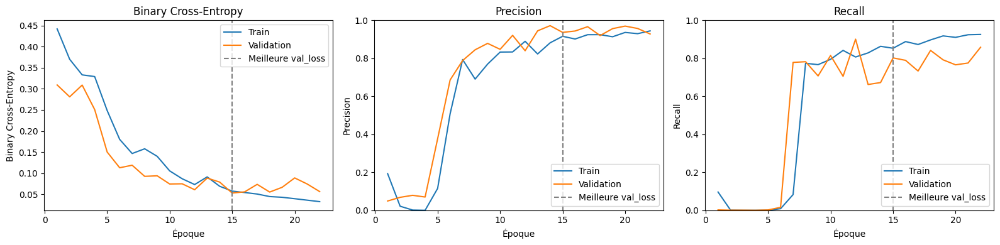

In [ ]:
transfer_epochs = np.arange(
    1, len(transfer_history_values["loss"]) + 1
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for axis, metric, title in zip(
    axes,
    ["loss", "precision", "recall"],
    ["Binary Cross-Entropy", "Precision", "Recall"],
):
    axis.plot(
        transfer_epochs,
        transfer_history_values[metric],
        label="Train",
    )
    axis.plot(
        transfer_epochs,
        transfer_history_values[f"val_{metric}"],
        label="Validation",
    )
    axis.axvline(
        transfer_best_epoch,
        color="gray",
        linestyle="--",
        label="Meilleure val_loss",
    )

    axis.set_xlabel("Époque")
    axis.set_ylabel(title)
    axis.set_title(title)
    axis.legend()

    if metric != "loss":
        axis.set_ylim(0, 1)

plt.tight_layout()
plt.savefig(
    transfer_run_dir / "learning_curves.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [ ]:
import shutil
from google.colab import files

transfer_archive_path = shutil.make_archive(
    base_name=str(transfer_run_dir),
    format="zip",
    root_dir=str(transfer_run_dir),
)

files.download(transfer_archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Étape 10 — Validation and Model Selection / Validation et sélection 🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑

In [ ]:
import json
import csv
import shutil
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

PROJECT_DIR = Path("/content/project-deeplearning")
DATA_DIR = PROJECT_DIR / "RoadAnomaly" / "RoadAnomaly"

model_run_dirs = {
    "baseline": (
        PROJECT_DIR
        / "outputs/baseline/20261030T144632_836334Z"
    ),
    "transfer": (
        PROJECT_DIR
        / "outputs/transfer_learning/20261030T144822_648308Z"
    ),
}

required_paths = [DATA_DIR / "frame_list.json"]

for run_dir in model_run_dirs.values():
    required_paths.extend([
        run_dir / "run_config.json",
        run_dir / "best_model.keras",
    ])

missing_paths = [
    str(path) for path in required_paths
    if not path.is_file()
]

if missing_paths:
    raise FileNotFoundError(
        "Fichiers à restaurer avant de poursuivre :\n"
        + "\n".join(missing_paths)
    )

print("Dataset, configurations et checkpoints présents.")

Dataset, configurations et checkpoints présents.


In [ ]:
model_configs = {
    name: json.loads(
        (run_dir / "run_config.json").read_text(encoding="utf-8")
    )
    for name, run_dir in model_run_dirs.items()
}

reference_config = model_configs["baseline"]

for key in [
    "splits", "group_by_name",
    "image_height", "image_width",
]:
    if reference_config[key] != model_configs["transfer"][key]:
        raise ValueError(
            f"Les expériences diffèrent sur : {key}"
        )

IMG_HEIGHT = int(reference_config["image_height"])
IMG_WIDTH = int(reference_config["image_width"])

saved_splits = reference_config["splits"]
group_by_name = reference_config["group_by_name"]

with (DATA_DIR / "frame_list.json").open(
    "r", encoding="utf-8"
) as file:
    frame_names = json.load(file)

if len(frame_names) != len(set(frame_names)):
    raise ValueError("Des noms sont répétés dans frame_list.json.")

split_sets = {}

for split in ["train", "validation", "test"]:
    names = saved_splits[split]

    if not names or len(names) != len(set(names)):
        raise ValueError(f"Partition vide ou noms répétés : {split}")

    split_sets[split] = set(names)

if set().union(*split_sets.values()) != set(frame_names):
    raise ValueError("Les partitions ne correspondent pas au dataset.")

for first, second in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    if split_sets[first] & split_sets[second]:
        raise ValueError(f"Images communes : {first} / {second}")

    first_groups = {
        group_by_name[name] for name in split_sets[first]
    }
    second_groups = {
        group_by_name[name] for name in split_sets[second]
    }

    if first_groups & second_groups:
        raise ValueError(f"Groupes communs : {first} / {second}")

val_records = []

for name in saved_splits["validation"]:
    if Path(name).name != name or "/" in name or "\\" in name:
        raise ValueError(f"Nom inattendu : {name}")

    image_path = DATA_DIR / "frames" / name
    mask_path = (
        image_path.with_suffix(".labels")
        / "labels_semantic.png"
    )

    if not image_path.is_file() or not mask_path.is_file():
        raise FileNotFoundError(
            f"Couple de validation incomplet : {name}"
        )

    val_records.append({
        "name": name,
        "image_path": image_path,
        "mask_path": mask_path,
    })

print("Dimensions d'entrée :", (IMG_HEIGHT, IMG_WIDTH))
print("Images de validation :", len(val_records))
print("Partitions et groupes déclarés compatibles.")

Dimensions d'entrée : (360, 640)
Images de validation : 9
Partitions et groupes déclarés compatibles.


In [ ]:
validation_models = {}
model_checkpoint_paths = {}

for name, run_dir in model_run_dirs.items():
    checkpoint_path = run_dir / "best_model.keras"

    model = tf.keras.models.load_model(
        checkpoint_path,
        compile=False,
    )

    expected_input = (IMG_HEIGHT, IMG_WIDTH, 3)
    expected_output = (IMG_HEIGHT, IMG_WIDTH, 1)

    if tuple(model.input_shape[1:]) != expected_input:
        raise ValueError(f"Entrée incompatible pour {name}.")

    if tuple(model.output_shape[1:]) != expected_output:
        raise ValueError(f"Sortie incompatible pour {name}.")

    validation_models[name] = model
    model_checkpoint_paths[name] = checkpoint_path

    print(
        f"{name} chargé — "
        f"entrée : {model.input_shape}, "
        f"sortie : {model.output_shape}"
    )

baseline chargé — entrée : (None, 360, 640, 3), sortie : (None, 360, 640, 1)
transfer chargé — entrée : (None, 360, 640, 3), sortie : (None, 360, 640, 1)


In [ ]:
def predict_at_native_resolution(model, record):
    with Image.open(record["image_path"]) as image:
        image = image.convert("RGB")
        image = image.resize(
            (IMG_WIDTH, IMG_HEIGHT),
            resample=Image.Resampling.BILINEAR,
        )
        prepared_image = (
            np.asarray(image, dtype=np.float32) / 255.0
        )

    with Image.open(record["mask_path"]) as mask:
        native_mask = np.array(mask)

    if native_mask.ndim != 2:
        raise ValueError(f"Masque invalide : {record['name']}")

    if not set(np.unique(native_mask)).issubset({0, 2}):
        raise ValueError(f"Labels inattendus : {record['name']}")

    probabilities = model(
        prepared_image[np.newaxis, ...],
        training=False,
    )[0]

    native_probabilities = tf.image.resize(
        probabilities,
        size=native_mask.shape,
        method="bilinear",
    )[..., 0]

    tf.debugging.assert_all_finite(
        native_probabilities,
        "Probabilités non finies.",
    )
    tf.debugging.assert_greater_equal(native_probabilities, 0.0)
    tf.debugging.assert_less_equal(native_probabilities, 1.0)

    return {
        "name": record["name"],
        "y_true": native_mask == 2,
        "probabilities": native_probabilities.numpy(),
    }


validation_predictions = {}

for name, model in validation_models.items():
    validation_predictions[name] = [
        predict_at_native_resolution(model, record)
        for record in val_records
    ]

    first_prediction = validation_predictions[name][0]

    print(
        f"{name} : {len(validation_predictions[name])} images, "
        f"résolution évaluée : "
        f"{first_prediction['y_true'].shape}"
    )

baseline : 9 images, résolution évaluée : (720, 1280)
transfer : 9 images, résolution évaluée : (720, 1280)


In [ ]:
def safe_divide(numerator, denominator):
    return numerator / denominator if denominator != 0 else 0.0


def scores_from_counts(tp, fp, fn, tn):
    f1 = safe_divide(2 * tp, 2 * tp + fp + fn)

    return {
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "tn": int(tn),
        "precision": float(safe_divide(tp, tp + fp)),
        "recall": float(safe_divide(tp, tp + fn)),
        "f1": float(f1),
        "dice": float(f1),
        "iou": float(safe_divide(tp, tp + fp + fn)),
    }


THRESHOLDS = np.round(
    np.linspace(0.05, 0.95, 19),
    decimals=2,
)

validation_results = {}

for name, predictions in validation_predictions.items():
    rows = []

    for threshold in THRESHOLDS:
        tp = fp = fn = tn = 0

        for prediction in predictions:
            y_true = prediction["y_true"]
            y_pred = prediction["probabilities"] > threshold

            tp += int(np.count_nonzero(y_true & y_pred))
            fp += int(np.count_nonzero(~y_true & y_pred))
            fn += int(np.count_nonzero(y_true & ~y_pred))
            tn += int(np.count_nonzero(~y_true & ~y_pred))

        row = scores_from_counts(tp, fp, fn, tn)
        row["threshold"] = float(threshold)
        rows.append(row)

    validation_results[name] = rows

print("Seuils évalués :", THRESHOLDS)
print("Calculs effectués uniquement sur validation.")

Seuils évalués : [0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7
 0.75 0.8  0.85 0.9  0.95]
Calculs effectués uniquement sur validation.


In [ ]:
best_validation_results = {}
selected_thresholds = {}

for name, rows in validation_results.items():
    best_row = max(
        rows,
        key=lambda row: (
            row["f1"],
            row["recall"],
            -abs(row["threshold"] - 0.5),
        ),
    )

    best_validation_results[name] = best_row
    selected_thresholds[name] = best_row["threshold"]

    print(f"\n{name.upper()}")
    print(f"Seuil retenu : {best_row['threshold']:.2f}")

    for metric in ["precision", "recall", "f1", "dice", "iou"]:
        print(f"{metric} : {best_row[metric]:.4f}")

selected_model_name = max(
    best_validation_results,
    key=lambda name: best_validation_results[name]["f1"],
)

if best_validation_results[selected_model_name]["f1"] == 0:
    raise RuntimeError(
        "Les deux modèles ont un F1 nul sur la grille. "
        "Il faut diagnostiquer les prédictions avant de poursuivre."
    )

print("\nModèle principal sur validation :", selected_model_name)


BASELINE
Seuil retenu : 0.15
precision : 0.3501
recall : 0.6507
f1 : 0.4552
dice : 0.4552
iou : 0.2947

TRANSFER
Seuil retenu : 0.35
precision : 0.8825
recall : 0.8716
f1 : 0.8770
dice : 0.8770
iou : 0.7809

Modèle principal sur validation : transfer


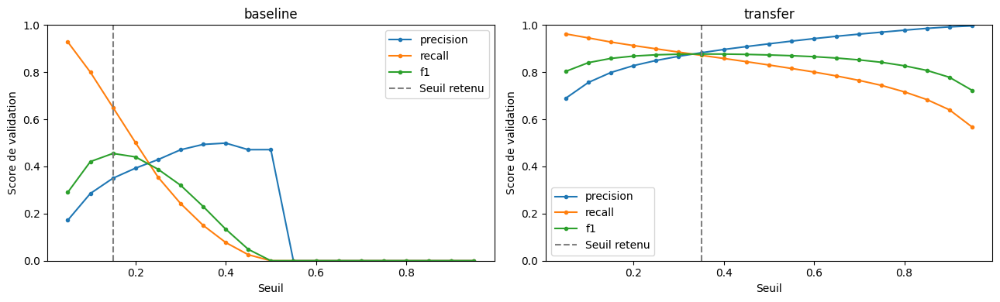

In [ ]:
selection_fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4),
)

for axis, (name, rows) in zip(
    axes,
    validation_results.items(),
):
    thresholds = [row["threshold"] for row in rows]

    for metric in ["precision", "recall", "f1"]:
        axis.plot(
            thresholds,
            [row[metric] for row in rows],
            marker="o",
            markersize=3,
            label=metric,
        )

    axis.axvline(
        selected_thresholds[name],
        color="gray",
        linestyle="--",
        label="Seuil retenu",
    )

    axis.set_title(name)
    axis.set_xlabel("Seuil")
    axis.set_ylabel("Score de validation")
    axis.set_ylim(0, 1)
    axis.legend()

selection_fig.tight_layout()
plt.show()

In [ ]:
selection_id = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

selection_dir = (
    PROJECT_DIR / "outputs" / "model_selection" / selection_id
)
selected_models_dir = selection_dir / "models"
selected_models_dir.mkdir(parents=True, exist_ok=False)

selection_payload = {
    "status": "fixed_before_test",
    "selection_dataset": "validation",
    "selection_metric": "pooled_pixel_f1",
    "evaluation_resolution": "native_mask_resolution",
    "probability_resize_method": "bilinear",
    "threshold_comparison": ">",
    "zero_division_value": 0.0,
    "threshold_grid": THRESHOLDS.tolist(),
    "primary_model": selected_model_name,
    "image_height": IMG_HEIGHT,
    "image_width": IMG_WIDTH,
    "validation_names": sorted(
        record["name"] for record in val_records
    ),
    "models": {},
}

for name, checkpoint_path in model_checkpoint_paths.items():
    saved_checkpoint = selected_models_dir / f"{name}.keras"
    shutil.copy2(checkpoint_path, saved_checkpoint)

    selection_payload["models"][name] = {
        "checkpoint_relative_path": str(
            saved_checkpoint.relative_to(PROJECT_DIR)
        ),
        "threshold": selected_thresholds[name],
        "validation_metrics": best_validation_results[name],
    }

    (selection_dir / f"{name}_run_config.json").write_text(
        json.dumps(
            model_configs[name],
            indent=2,
            ensure_ascii=False,
            allow_nan=False,
        ),
        encoding="utf-8",
    )

    rows = validation_results[name]

    with (selection_dir / f"{name}_thresholds.csv").open(
        "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

selection_path = selection_dir / "validation_selection.json"

selection_path.write_text(
    json.dumps(
        selection_payload,
        indent=2,
        ensure_ascii=False,
        allow_nan=False,
    ),
    encoding="utf-8",
)

selection_fig.savefig(
    selection_dir / "validation_threshold_curves.png",
    dpi=150,
    bbox_inches="tight",
)

print("Sélection sauvegardée :", selection_path)
print("Seuils :", selected_thresholds)

Sélection sauvegardée : /content/project-deeplearning/outputs/model_selection/20261030T170429_728027Z/validation_selection.json
Seuils : {'baseline': 0.15, 'transfer': 0.35}


In [ ]:
from google.colab import files

selection_archive_path = shutil.make_archive(
    base_name=str(selection_dir),
    format="zip",
    root_dir=str(PROJECT_DIR),
    base_dir=str(selection_dir.relative_to(PROJECT_DIR)),
)

print("Archive :", selection_archive_path)
files.download(selection_archive_path)

Archive : /content/project-deeplearning/outputs/model_selection/20261030T170429_728027Z.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

11. Final Performance Evaluation / Évaluation finale 🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑🛑

In [ ]:
import json
import csv
import time
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

PROJECT_DIR = Path("/content/project-deeplearning").resolve()
DATA_DIR = PROJECT_DIR / "RoadAnomaly" / "RoadAnomaly"

# Réutiliser le protocole déjà sélectionné dans cette session.
if "selection_path" in globals():
    selection_path = Path(selection_path)

else:
    selection_root = PROJECT_DIR / "outputs" / "model_selection"

    candidates = (
        sorted(selection_root.rglob("validation_selection.json"))
        if selection_root.is_dir()
        else []
    )

    if len(candidates) != 1:
        print("Protocoles disponibles :")
        for candidate in candidates:
            print(candidate)

        raise RuntimeError(
            "Il faut identifier exactement un protocole. "
            "Définis selection_path avec le chemin voulu, puis relance."
        )

    selection_path = candidates[0]

selection_path = selection_path.resolve()

if not selection_path.is_relative_to(PROJECT_DIR):
    raise ValueError("Le protocole doit appartenir au dossier du projet.")

if not selection_path.is_file():
    raise FileNotFoundError(f"Protocole absent : {selection_path}")

selection_payload = json.loads(
    selection_path.read_text(encoding="utf-8")
)

expected_protocol = {
    "status": "fixed_before_test",
    "evaluation_resolution": "native_mask_resolution",
    "probability_resize_method": "bilinear",
    "threshold_comparison": ">",
    "zero_division_value": 0.0,
}

for key, expected_value in expected_protocol.items():
    if selection_payload.get(key) != expected_value:
        raise ValueError(f"Protocole inattendu pour : {key}")

selection_dir = selection_path.parent
IMG_HEIGHT = int(selection_payload["image_height"])
IMG_WIDTH = int(selection_payload["image_width"])

print("Protocole :", selection_path)
print("Modèle principal :", selection_payload["primary_model"])

for name, model_info in selection_payload["models"].items():
    print(f"{name} — seuil figé : {model_info['threshold']}")

Protocole : /content/project-deeplearning/outputs/model_selection/20261030T170429_728027Z/validation_selection.json
Modèle principal : transfer
baseline — seuil figé : 0.15
transfer — seuil figé : 0.35


In [ ]:
evaluation_configs = {}

for model_name in selection_payload["models"]:
    config_path = selection_dir / f"{model_name}_run_config.json"

    evaluation_configs[model_name] = json.loads(
        config_path.read_text(encoding="utf-8")
    )

reference_config = evaluation_configs["baseline"]

for model_name, config in evaluation_configs.items():
    for key in [
        "splits", "group_by_name",
        "image_height", "image_width",
    ]:
        if config[key] != reference_config[key]:
            raise ValueError(
                f"Configurations incompatibles : {model_name}, {key}"
            )

if (
    reference_config["image_height"] != IMG_HEIGHT
    or reference_config["image_width"] != IMG_WIDTH
):
    raise ValueError("Dimensions incompatibles avec le protocole.")

saved_splits = reference_config["splits"]
group_by_name = reference_config["group_by_name"]

if sorted(saved_splits["validation"]) != sorted(
    selection_payload["validation_names"]
):
    raise ValueError("La validation enregistrée ne correspond pas.")

split_sets = {}

for split in ["train", "validation", "test"]:
    names = saved_splits[split]

    if not names or len(names) != len(set(names)):
        raise ValueError(f"Partition vide ou noms répétés : {split}")

    split_sets[split] = set(names)

for first, second in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    if split_sets[first] & split_sets[second]:
        raise ValueError(f"Images communes : {first} / {second}")

    first_groups = {
        group_by_name[name] for name in split_sets[first]
    }
    second_groups = {
        group_by_name[name] for name in split_sets[second]
    }

    if first_groups & second_groups:
        raise ValueError(f"Groupes communs : {first} / {second}")

test_records = []

for name in saved_splits["test"]:
    if Path(name).name != name or "/" in name or "\\" in name:
        raise ValueError(f"Nom de fichier inattendu : {name}")

    image_path = DATA_DIR / "frames" / name
    mask_path = (
        image_path.with_suffix(".labels")
        / "labels_semantic.png"
    )

    if not image_path.is_file() or not mask_path.is_file():
        raise FileNotFoundError(f"Couple de test incomplet : {name}")

    test_records.append({
        "name": name,
        "image_path": image_path,
        "mask_path": mask_path,
    })

print("Images de test :", len(test_records))
print("Séparation des images et des groupes déclarés vérifiée.")

Images de test : 12
Séparation des images et des groupes déclarés vérifiée.


In [ ]:
def safe_divide(numerator, denominator):
    return numerator / denominator if denominator != 0 else 0.0


def scores_from_counts(tp, fp, fn, tn):
    f1 = safe_divide(2 * tp, 2 * tp + fp + fn)

    return {
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "tn": int(tn),
        "precision": float(safe_divide(tp, tp + fp)),
        "recall": float(safe_divide(tp, tp + fn)),
        "f1": float(f1),
        "dice": float(f1),
        "iou": float(safe_divide(tp, tp + fp + fn)),
    }


def predict_at_native_resolution(model, record):
    with Image.open(record["image_path"]) as image:
        image = image.convert("RGB")
        image = image.resize(
            (IMG_WIDTH, IMG_HEIGHT),
            resample=Image.Resampling.BILINEAR,
        )
        prepared_image = (
            np.asarray(image, dtype=np.float32) / 255.0
        )

    with Image.open(record["mask_path"]) as mask:
        native_mask = np.array(mask)

    if native_mask.ndim != 2:
        raise ValueError(f"Masque invalide : {record['name']}")

    if not set(np.unique(native_mask)).issubset({0, 2}):
        raise ValueError(f"Labels inattendus : {record['name']}")

    probabilities = model(
        prepared_image[np.newaxis, ...],
        training=False,
    )[0]

    tf.debugging.assert_shapes([
        (probabilities, (IMG_HEIGHT, IMG_WIDTH, 1))
    ])

    native_probabilities = tf.image.resize(
        probabilities,
        size=native_mask.shape,
        method="bilinear",
    )[..., 0]

    tf.debugging.assert_all_finite(
        native_probabilities, "Probabilités non finies."
    )
    tf.debugging.assert_greater_equal(native_probabilities, 0.0)
    tf.debugging.assert_less_equal(native_probabilities, 1.0)

    return native_mask == 2, native_probabilities.numpy()

In [ ]:
evaluation_dir = selection_dir / "final_evaluation"
evaluation_dir.mkdir(exist_ok=True)

test_results_path = evaluation_dir / "test_results.json"

if test_results_path.is_file():
    test_results = json.loads(
        test_results_path.read_text(encoding="utf-8")
    )
    print("Résultats déjà enregistrés : lecture sans nouvelle inférence.")

else:
    predictions_dir = evaluation_dir / "predictions"
    predictions_dir.mkdir(exist_ok=True)

    test_results = {
        "dataset": "test",
        "primary_model": selection_payload["primary_model"],
        "image_count": len(test_records),
        "evaluation_resolution": "native_mask_resolution",
        "threshold_comparison": ">",
        "zero_division_value": 0.0,
        "tensorflow_version": tf.__version__,
        "models": {},
    }

    for model_name, model_info in selection_payload["models"].items():
        checkpoint_path = (
            PROJECT_DIR / model_info["checkpoint_relative_path"]
        ).resolve()

        if not checkpoint_path.is_relative_to(PROJECT_DIR):
            raise ValueError("Checkpoint situé hors du projet.")

        if not checkpoint_path.is_file():
            raise FileNotFoundError(checkpoint_path)

        threshold = float(model_info["threshold"])

        if not np.isfinite(threshold) or not 0 <= threshold <= 1:
            raise ValueError(f"Seuil invalide pour {model_name}")

        model = tf.keras.models.load_model(
            checkpoint_path,
            compile=False,
        )

        total_tp = total_fp = total_fn = total_tn = 0
        per_image_metrics = []

        start_time = time.perf_counter()

        for record in test_records:
            y_true, probabilities = predict_at_native_resolution(
                model, record
            )
            y_pred = probabilities > threshold

            tp = int(np.count_nonzero(y_true & y_pred))
            fp = int(np.count_nonzero(~y_true & y_pred))
            fn = int(np.count_nonzero(y_true & ~y_pred))
            tn = int(np.count_nonzero(~y_true & ~y_pred))

            total_tp += tp
            total_fp += fp
            total_fn += fn
            total_tn += tn

            prediction_path = predictions_dir / (
                f"{model_name}__{Path(record['name']).stem}.npz"
            )

            np.savez_compressed(
                prediction_path,
                probabilities=probabilities.astype(np.float32),
            )

            row = scores_from_counts(tp, fp, fn, tn)
            row.update({
                "name": record["name"],
                "threshold": threshold,
                "prediction_relative_path": str(
                    prediction_path.relative_to(PROJECT_DIR)
                ),
            })
            per_image_metrics.append(row)

        test_results["models"][model_name] = {
            "threshold": threshold,
            "global_metrics": scores_from_counts(
                total_tp, total_fp, total_fn, total_tn
            ),
            "per_image_metrics": per_image_metrics,
            "evaluation_duration_seconds": (
                time.perf_counter() - start_time
            ),
        }

        print(f"{model_name} : évaluation terminée.")

        del model

    test_results_path.write_text(
        json.dumps(
            test_results,
            indent=2,
            ensure_ascii=False,
            allow_nan=False,
        ),
        encoding="utf-8",
    )

    print("Résultats enregistrés :", test_results_path)

baseline : évaluation terminée.
transfer : évaluation terminée.
Résultats enregistrés : /content/project-deeplearning/outputs/model_selection/20261030T170429_728027Z/final_evaluation/test_results.json


In [ ]:
print("ÉVALUATION FINALE — TEST")
print("Nombre d'images :", test_results["image_count"])
print("Modèle principal fixé sur validation :", test_results["primary_model"])

print(
    "\nModèle       | Seuil | Precision | Recall | F1     | Dice   | IoU"
)

for model_name, result in test_results["models"].items():
    scores = result["global_metrics"]

    print(
        f"{model_name:<12} | "
        f"{result['threshold']:.2f}  | "
        f"{scores['precision']:.4f}    | "
        f"{scores['recall']:.4f} | "
        f"{scores['f1']:.4f} | "
        f"{scores['dice']:.4f} | "
        f"{scores['iou']:.4f}"
    )

ÉVALUATION FINALE — TEST
Nombre d'images : 12
Modèle principal fixé sur validation : transfer

Modèle       | Seuil | Precision | Recall | F1     | Dice   | IoU
baseline     | 0.15  | 0.3552    | 0.6961 | 0.4704 | 0.4704 | 0.3075
transfer     | 0.35  | 0.7947    | 0.6547 | 0.7179 | 0.7179 | 0.5600


In [ ]:
for model_name, result in test_results["models"].items():
    rows = result["per_image_metrics"]

    f1_values = np.array([row["f1"] for row in rows])
    iou_values = np.array([row["iou"] for row in rows])

    print(f"\n{model_name.upper()} — métriques par image")

    print(
        "F1 : "
        f"moyenne={f1_values.mean():.4f}, "
        f"médiane={np.median(f1_values):.4f}, "
        f"min={f1_values.min():.4f}, "
        f"max={f1_values.max():.4f}"
    )

    print(
        "IoU : "
        f"moyenne={iou_values.mean():.4f}, "
        f"médiane={np.median(iou_values):.4f}, "
        f"min={iou_values.min():.4f}, "
        f"max={iou_values.max():.4f}"
    )

    csv_path = evaluation_dir / f"{model_name}_per_image_metrics.csv"

    with csv_path.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(
            file,
            fieldnames=list(rows[0]),
        )
        writer.writeheader()
        writer.writerows(rows)


BASELINE — métriques par image
F1 : moyenne=0.4585, médiane=0.4649, min=0.1187, max=0.8619
IoU : moyenne=0.3258, médiane=0.3034, min=0.0631, max=0.7574

TRANSFER — métriques par image
F1 : moyenne=0.6741, médiane=0.7504, min=0.1436, max=0.9280
IoU : moyenne=0.5497, médiane=0.6005, min=0.0773, max=0.8656


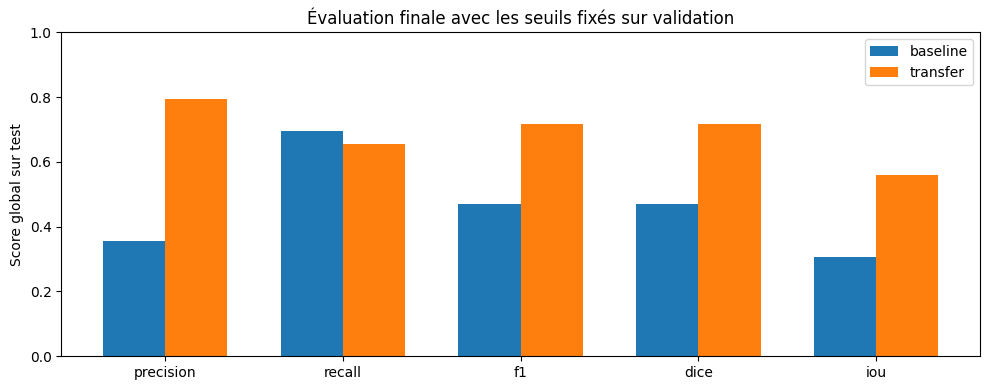

In [ ]:
metric_names = ["precision", "recall", "f1", "dice", "iou"]
model_names = list(test_results["models"])

x = np.arange(len(metric_names))
bar_width = 0.35

evaluation_fig, axis = plt.subplots(figsize=(10, 4))

for index, model_name in enumerate(model_names):
    values = [
        test_results["models"][model_name]["global_metrics"][metric]
        for metric in metric_names
    ]

    offset = (index - (len(model_names) - 1) / 2) * bar_width

    axis.bar(
        x + offset,
        values,
        width=bar_width,
        label=model_name,
    )

axis.set_xticks(x)
axis.set_xticklabels(metric_names)
axis.set_ylim(0, 1)
axis.set_ylabel("Score global sur test")
axis.set_title("Évaluation finale avec les seuils fixés sur validation")
axis.legend()

evaluation_fig.tight_layout()
evaluation_fig.savefig(
    evaluation_dir / "test_metrics_comparison.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [ ]:
from google.colab import files

final_archive_path = shutil.make_archive(
    base_name=str(selection_dir) + "_with_test",
    format="zip",
    root_dir=str(PROJECT_DIR),
    base_dir=str(selection_dir.relative_to(PROJECT_DIR)),
)

print("Archive complète :", final_archive_path)
files.download(final_archive_path)

Archive complète : /content/project-deeplearning/outputs/model_selection/20261030T170429_728027Z_with_test.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Étape 12 — Results Analysis / Analyse des résultats

In [ ]:
import json
import csv
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image

PROJECT_DIR = Path("/content/project-deeplearning").resolve()
DATA_DIR = PROJECT_DIR / "RoadAnomaly" / "RoadAnomaly"

if "test_results_path" in globals():
    test_results_path = Path(test_results_path)

else:
    results_root = PROJECT_DIR / "outputs" / "model_selection"

    candidates = (
        sorted(results_root.rglob("test_results.json"))
        if results_root.is_dir()
        else []
    )

    if len(candidates) != 1:
        print("Résultats disponibles :")
        for candidate in candidates:
            print(candidate)

        raise RuntimeError(
            "Définis test_results_path avec le fichier de l'expérience "
            "à analyser, puis relance."
        )

    test_results_path = candidates[0]

test_results_path = test_results_path.resolve()

if not test_results_path.is_relative_to(PROJECT_DIR):
    raise ValueError("Les résultats doivent appartenir au projet.")

test_results = json.loads(
    test_results_path.read_text(encoding="utf-8")
)

evaluation_dir = test_results_path.parent
selection_dir = evaluation_dir.parent

selection_payload = json.loads(
    (selection_dir / "validation_selection.json").read_text(
        encoding="utf-8"
    )
)

primary_model = selection_payload["primary_model"]

if test_results["primary_model"] != primary_model:
    raise ValueError("Incohérence sur le modèle principal.")

if set(test_results["models"]) != {"baseline", "transfer"}:
    raise ValueError("Les deux approches attendues sont absentes.")

per_image_by_model = {
    model_name: {
        row["name"]: row
        for row in result["per_image_metrics"]
    }
    for model_name, result in test_results["models"].items()
}

if (
    set(per_image_by_model["baseline"])
    != set(per_image_by_model["transfer"])
):
    raise ValueError("Les modèles n'ont pas été évalués sur les mêmes images.")

analysis_dir = evaluation_dir / "analysis"
analysis_dir.mkdir(exist_ok=True)

print("Résultats chargés :", test_results_path)
print("Modèle principal fixé sur validation :", primary_model)
print("Images analysées :", test_results["image_count"])

Résultats chargés : /content/project-deeplearning/outputs/model_selection/20261030T170429_728027Z/final_evaluation/test_results.json
Modèle principal fixé sur validation : transfer
Images analysées : 12


In [ ]:
comparison_rows = []

for model_name in ["baseline", "transfer"]:
    validation_scores = selection_payload["models"][
        model_name
    ]["validation_metrics"]

    test_scores = test_results["models"][
        model_name
    ]["global_metrics"]

    print(f"\n{model_name.upper()}")
    print("Métrique  | Validation | Test   | Écart test - validation")

    for metric in ["precision", "recall", "f1", "iou"]:
        validation_value = validation_scores[metric]
        test_value = test_scores[metric]
        difference = test_value - validation_value

        print(
            f"{metric:<9} | "
            f"{validation_value:.4f}     | "
            f"{test_value:.4f} | "
            f"{difference:+.4f}"
        )

        comparison_rows.append({
            "model": model_name,
            "metric": metric,
            "validation": validation_value,
            "test": test_value,
            "test_minus_validation": difference,
        })

with (analysis_dir / "validation_test_comparison.csv").open(
    "w", newline="", encoding="utf-8"
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=list(comparison_rows[0]),
    )
    writer.writeheader()
    writer.writerows(comparison_rows)


BASELINE
Métrique  | Validation | Test   | Écart test - validation
precision | 0.3501     | 0.3552 | +0.0051
recall    | 0.6507     | 0.6961 | +0.0454
f1        | 0.4552     | 0.4704 | +0.0151
iou       | 0.2947     | 0.3075 | +0.0128

TRANSFER
Métrique  | Validation | Test   | Écart test - validation
precision | 0.8825     | 0.7947 | -0.0878
recall    | 0.8716     | 0.6547 | -0.2169
f1        | 0.8770     | 0.7179 | -0.1591
iou       | 0.7809     | 0.5600 | -0.2209


In [ ]:
test_names = sorted(per_image_by_model["baseline"])

image_comparison_rows = []

for name in test_names:
    baseline_scores = per_image_by_model["baseline"][name]
    transfer_scores = per_image_by_model["transfer"][name]

    image_comparison_rows.append({
        "name": name,
        "baseline_f1": baseline_scores["f1"],
        "transfer_f1": transfer_scores["f1"],
        "f1_difference": (
            transfer_scores["f1"] - baseline_scores["f1"]
        ),
        "baseline_iou": baseline_scores["iou"],
        "transfer_iou": transfer_scores["iou"],
    })

print("Différence de F1 : transfert - baseline\n")

for row in sorted(
    image_comparison_rows,
    key=lambda row: row["f1_difference"],
):
    print(f"{row['f1_difference']:+.4f} | {row['name']}")

with (analysis_dir / "per_image_model_comparison.csv").open(
    "w", newline="", encoding="utf-8"
) as file:
    writer = csv.DictWriter(
        file,
        fieldnames=list(image_comparison_rows[0]),
    )
    writer.writeheader()
    writer.writerows(image_comparison_rows)

Différence de F1 : transfert - baseline

-0.4733 | obstacles07_czech_hedgehog.webp
-0.0713 | obstacles05_cardboard_czech_hedgehog.webp
+0.0091 | obstacles03_cardboard_czech_hedgehog.webp
+0.0536 | animals04_17_animal_casualties_so_far_in_2006.webp
+0.1163 | animals03_Zebras_in_the_road.webp
+0.1517 | obstacles06_cardboard_czech_hedgehog.webp
+0.2509 | animals05_cows_near_Phonsavan_Laos.webp
+0.3171 | obstacles04_cardboard_czech_hedgehog.webp
+0.4624 | animals14_Dekemhare_Road.webp
+0.5212 | cones07.webp
+0.6134 | animals12_Collared_Peccary_crossing_the_road.webp
+0.6363 | animals11_Cock_Pheasant_on_Romford_Road.webp


In [ ]:
primary_rows = sorted(
    per_image_by_model[primary_model].values(),
    key=lambda row: row["f1"],
)

candidate_names = [
    primary_rows[0]["name"],
    primary_rows[len(primary_rows) // 2]["name"],
    primary_rows[-1]["name"],
]

qualitative_names = list(dict.fromkeys(candidate_names))

print("Exemples sélectionnés selon le F1 du modèle principal :")

for name in qualitative_names:
    row = per_image_by_model[primary_model][name]
    print(f"- {name} : F1={row['f1']:.4f}")

Exemples sélectionnés selon le F1 du modèle principal :
- obstacles07_czech_hedgehog.webp : F1=0.1436
- animals11_Cock_Pheasant_on_Romford_Road.webp : F1=0.7550
- animals12_Collared_Peccary_crossing_the_road.webp : F1=0.9280


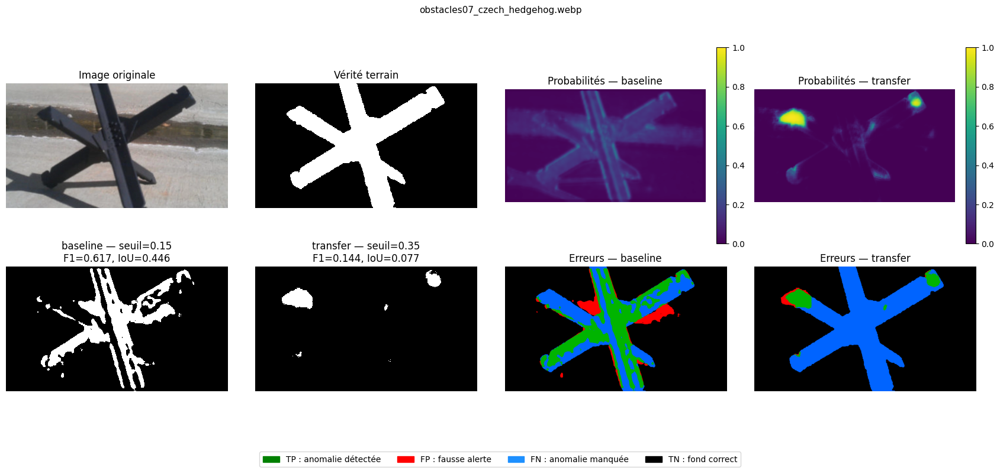

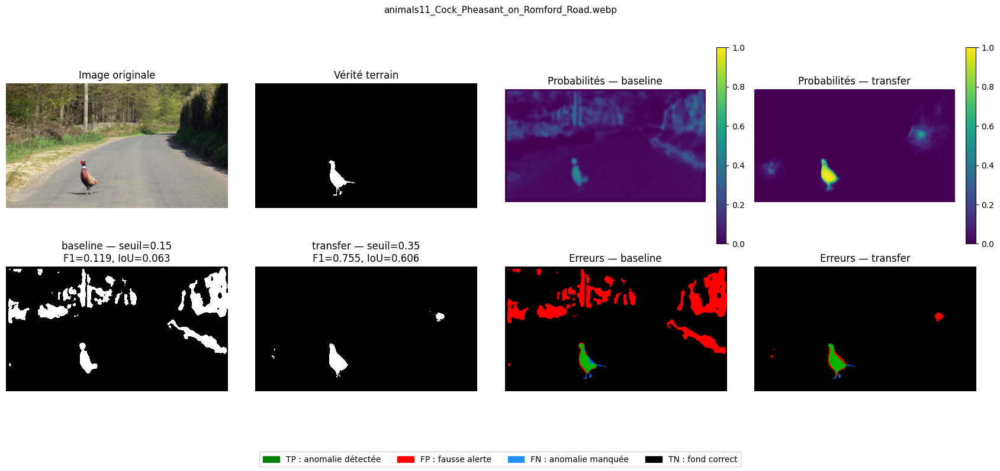

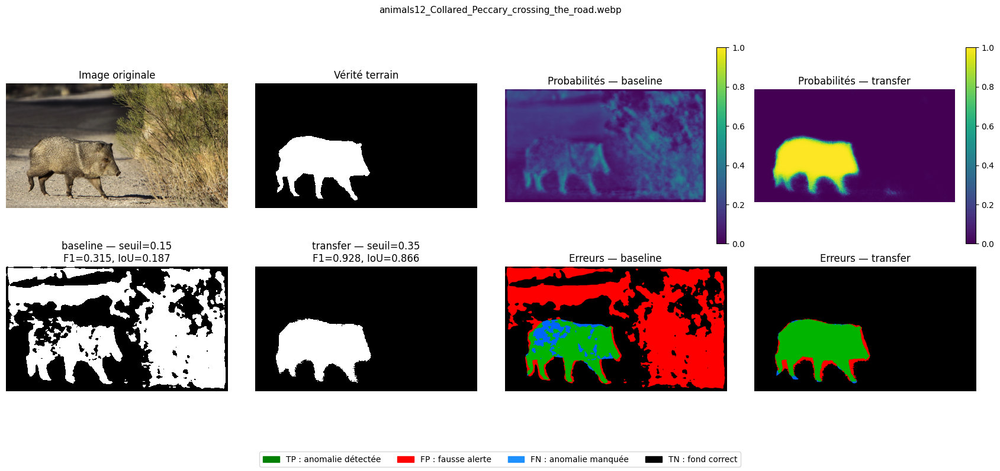

In [ ]:
def load_saved_prediction(model_name, image_name):
    row = per_image_by_model[model_name][image_name]

    prediction_path = (
        PROJECT_DIR / row["prediction_relative_path"]
    ).resolve()

    if not prediction_path.is_relative_to(PROJECT_DIR):
        raise ValueError("Prédiction située hors du projet.")

    with np.load(prediction_path, allow_pickle=False) as archive:
        probabilities = archive["probabilities"].copy()

    if not np.all(np.isfinite(probabilities)):
        raise ValueError("Probabilités non finies.")

    if probabilities.min() < 0 or probabilities.max() > 1:
        raise ValueError("Probabilités hors de [0, 1].")

    return probabilities


def make_error_map(y_true, y_pred):
    error_map = np.zeros((*y_true.shape, 3), dtype=np.uint8)

    error_map[y_true & y_pred] = [0, 180, 0]       # TP : vert
    error_map[~y_true & y_pred] = [255, 0, 0]      # FP : rouge
    error_map[y_true & ~y_pred] = [0, 100, 255]    # FN : bleu

    return error_map


def show_test_comparison(image_name):
    image_path = DATA_DIR / "frames" / image_name
    mask_path = (
        image_path.with_suffix(".labels")
        / "labels_semantic.png"
    )

    with Image.open(image_path) as image:
        rgb_image = np.array(image.convert("RGB"))

    with Image.open(mask_path) as mask:
        y_true = np.array(mask) == 2

    probabilities = {}
    predictions = {}

    for model_name in ["baseline", "transfer"]:
        probabilities[model_name] = load_saved_prediction(
            model_name, image_name
        )

        if probabilities[model_name].shape != y_true.shape:
            raise ValueError("Dimensions prédiction–annotation incompatibles.")

        threshold = test_results["models"][model_name]["threshold"]
        predictions[model_name] = (
            probabilities[model_name] > threshold
        )

    fig, axes = plt.subplots(2, 4, figsize=(17, 8))

    axes[0, 0].imshow(rgb_image)
    axes[0, 0].set_title("Image originale")

    axes[0, 1].imshow(
        y_true, cmap="gray", vmin=0, vmax=1,
        interpolation="nearest",
    )
    axes[0, 1].set_title("Vérité terrain")

    for column, model_name in enumerate(
        ["baseline", "transfer"], start=2
    ):
        probability_plot = axes[0, column].imshow(
            probabilities[model_name],
            cmap="viridis",
            vmin=0,
            vmax=1,
        )
        axes[0, column].set_title(
            f"Probabilités — {model_name}"
        )
        fig.colorbar(
            probability_plot,
            ax=axes[0, column],
            fraction=0.046,
        )

    for column, model_name in enumerate(["baseline", "transfer"]):
        scores = per_image_by_model[model_name][image_name]
        threshold = test_results["models"][model_name]["threshold"]

        axes[1, column].imshow(
            predictions[model_name],
            cmap="gray",
            vmin=0,
            vmax=1,
            interpolation="nearest",
        )
        axes[1, column].set_title(
            f"{model_name} — seuil={threshold:.2f}\n"
            f"F1={scores['f1']:.3f}, IoU={scores['iou']:.3f}"
        )

        axes[1, column + 2].imshow(
            make_error_map(y_true, predictions[model_name])
        )
        axes[1, column + 2].set_title(
            f"Erreurs — {model_name}"
        )

    for axis in axes.ravel():
        axis.axis("off")

    fig.legend(
        handles=[
            Patch(color="green", label="TP : anomalie détectée"),
            Patch(color="red", label="FP : fausse alerte"),
            Patch(color="dodgerblue", label="FN : anomalie manquée"),
            Patch(color="black", label="TN : fond correct"),
        ],
        loc="lower center",
        ncol=4,
    )

    fig.suptitle(image_name, fontsize=11)
    fig.tight_layout(rect=[0, 0.07, 1, 0.95])

    fig.savefig(
        analysis_dir / f"{Path(image_name).stem}_comparison.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()


for name in qualitative_names:
    show_test_comparison(name)

In [ ]:
from google.colab import files

analysis_archive_path = shutil.make_archive(
    base_name=str(selection_dir) + "_with_analysis",
    format="zip",
    root_dir=str(PROJECT_DIR),
    base_dir=str(selection_dir.relative_to(PROJECT_DIR)),
)

print("Archive :", analysis_archive_path)
files.download(analysis_archive_path)

Archive : /content/project-deeplearning/outputs/model_selection/20261030T170429_728027Z_with_analysis.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

13. Technical Reporting / Rapport technique 🛑🛑🛑🛑🛑🛑🛑🛑

In [ ]:
import json
import shutil
from pathlib import Path

import numpy as np

PROJECT_DIR = Path("/content/project-deeplearning").resolve()

if "test_results_path" in globals():
    test_results_path = Path(test_results_path)

else:
    results_root = PROJECT_DIR / "outputs" / "model_selection"

    candidates = (
        sorted(results_root.rglob("test_results.json"))
        if results_root.is_dir()
        else []
    )

    if len(candidates) != 1:
        print("Résultats disponibles :")
        for candidate in candidates:
            print(candidate)

        raise RuntimeError(
            "Définis test_results_path avec l'expérience à rapporter."
        )

    test_results_path = candidates[0]

test_results_path = test_results_path.resolve()

if not test_results_path.is_relative_to(PROJECT_DIR):
    raise ValueError("Les résultats doivent appartenir au projet.")

evaluation_dir = test_results_path.parent
selection_dir = evaluation_dir.parent

test_results = json.loads(
    test_results_path.read_text(encoding="utf-8")
)

selection_payload = json.loads(
    (selection_dir / "validation_selection.json").read_text(
        encoding="utf-8"
    )
)

report_configs = {
    name: json.loads(
        (selection_dir / f"{name}_run_config.json").read_text(
            encoding="utf-8"
        )
    )
    for name in ["baseline", "transfer"]
}

reference_config = report_configs["baseline"]

if report_configs["transfer"]["splits"] != reference_config["splits"]:
    raise ValueError("Les expériences utilisent des partitions différentes.")

if (
    test_results["primary_model"]
    != selection_payload["primary_model"]
):
    raise ValueError("Incohérence sur le modèle principal.")

expected_test_names = set(reference_config["splits"]["test"])

for name in ["baseline", "transfer"]:
    result = test_results["models"][name]
    evaluated_names = {
        row["name"] for row in result["per_image_metrics"]
    }

    if evaluated_names != expected_test_names:
        raise ValueError(f"Images évaluées incohérentes pour {name}.")

    if result["threshold"] != selection_payload["models"][name]["threshold"]:
        raise ValueError(f"Seuil incohérent pour {name}.")

print("Expérience identifiée :", selection_dir.name)
print("Résultats et configurations compatibles.")

Expérience identifiée : 20261030T170429_728027Z
Résultats et configurations compatibles.


In [ ]:
REPORT_DECIMALS = 4


def format_number(value):
    return f"{float(value):.{REPORT_DECIMALS}f}"


def markdown_table(headers, rows):
    def clean(value):
        return str(value).replace("|", r"\|")

    lines = [
        "| " + " | ".join(map(clean, headers)) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]

    lines.extend(
        "| " + " | ".join(map(clean, row)) + " |"
        for row in rows
    )

    return "\n".join(lines)


split_table = markdown_table(
    ["Partition", "Nombre d’images"],
    [
        [split, len(reference_config["splits"][split])]
        for split in ["train", "validation", "test"]
    ],
)

training_table = markdown_table(
    [
        "Modèle", "Learning rate", "Batch size",
        "Maximum d’époques", "Patience", "Seuil retenu",
    ],
    [
        [
            name,
            report_configs[name]["learning_rate"],
            report_configs[name]["batch_size"],
            report_configs[name]["max_epochs"],
            report_configs[name]["patience"],
            format_number(
                selection_payload["models"][name]["threshold"]
            ),
        ]
        for name in ["baseline", "transfer"]
    ],
)

result_rows = []

for name in ["baseline", "transfer"]:
    for phase in ["validation", "test"]:
        scores = (
            selection_payload["models"][name]["validation_metrics"]
            if phase == "validation"
            else test_results["models"][name]["global_metrics"]
        )

        result_rows.append([
            name,
            phase,
            *[
                format_number(scores[metric])
                for metric in [
                    "precision", "recall", "f1", "dice", "iou"
                ]
            ],
        ])

results_table = markdown_table(
    ["Modèle", "Ensemble", "Precision", "Recall", "F1", "Dice", "IoU"],
    result_rows,
)

per_image_rows = []

for name in ["baseline", "transfer"]:
    values = np.array([
        row["f1"]
        for row in test_results["models"][name]["per_image_metrics"]
    ])

    per_image_rows.append([
        name,
        format_number(values.mean()),
        format_number(np.median(values)),
        format_number(values.min()),
        format_number(values.max()),
    ])

per_image_table = markdown_table(
    ["Modèle", "F1 moyen", "F1 médian", "F1 minimum", "F1 maximum"],
    per_image_rows,
)

print(results_table)

| Modèle | Ensemble | Precision | Recall | F1 | Dice | IoU |
| --- | --- | --- | --- | --- | --- | --- |
| baseline | validation | 0.3501 | 0.6507 | 0.4552 | 0.4552 | 0.2947 |
| baseline | test | 0.3552 | 0.6961 | 0.4704 | 0.4704 | 0.3075 |
| transfer | validation | 0.8825 | 0.8716 | 0.8770 | 0.8770 | 0.7809 |
| transfer | test | 0.7947 | 0.6547 | 0.7179 | 0.7179 | 0.5600 |


In [ ]:
report_dir = selection_dir / "technical_report"
figures_dir = report_dir / "figures"
evidence_dir = report_dir / "evidence"

figures_dir.mkdir(parents=True, exist_ok=True)
evidence_dir.mkdir(exist_ok=True)

figure_candidates = [
    selection_dir / "validation_threshold_curves.png",
    evaluation_dir / "test_metrics_comparison.png",
]

analysis_dir = evaluation_dir / "analysis"

if analysis_dir.is_dir():
    figure_candidates.extend(
        sorted(analysis_dir.glob("*_comparison.png"))
    )

figure_sections = []

for index, source in enumerate(figure_candidates, start=1):
    if not source.is_file():
        continue

    destination = figures_dir / f"{index:02d}_{source.name}"
    shutil.copy2(source, destination)

    figure_sections.append(
        f"### Figure {index}\n\n"
        f"![Figure {index}](figures/{destination.name})\n\n"
        "[À COMPLÉTER : légende, observation et interprétation.]\n"
    )

figure_markdown = (
    "\n".join(figure_sections)
    if figure_sections
    else "[À COMPLÉTER : insérer les figures des étapes 10 à 12.]"
)

evidence_sources = [
    selection_dir / "validation_selection.json",
    test_results_path,
    selection_dir / "baseline_run_config.json",
    selection_dir / "transfer_run_config.json",
]

for source in evidence_sources:
    shutil.copy2(source, evidence_dir / source.name)

print("Figures copiées :", len(figure_sections))
print("Dossier du rapport :", report_dir)

Figures copiées : 5
Dossier du rapport : /content/project-deeplearning/outputs/model_selection/20261030T170429_728027Z/technical_report


In [ ]:
primary_model = selection_payload["primary_model"]

total_observations = sum(
    len(names)
    for names in reference_config["splits"].values()
)

input_height = reference_config["image_height"]
input_width = reference_config["image_width"]

report_text = f"""# Segmentation des anomalies routières avec RoadAnomaly

**Groupe :** [À COMPLÉTER : noms et identifiants]
**Module :** Deep Learning
**Expérience :** {selection_dir.name}

## 1. Problématique et objectif

Le projet étudie la localisation d’anomalies dans des scènes routières.
À partir d’une image RGB, les modèles produisent un score d’anomalie
pour chaque pixel, puis un masque binaire.

Il s’agit d’une segmentation sémantique binaire supervisée.
Le projet ne cherche pas à distinguer les espèces animales ou les
catégories individuelles d’obstacles.

## 2. Dataset

Les partitions enregistrées couvrent {total_observations} observations.
Chaque observation associe une image WebP à un masque sémantique PNG.
Les labels originaux sont 0 pour le fond et 2 pour l’anomalie.

Les fichiers d’instances et les visualisations colorées ne sont pas utilisés
comme cibles d’apprentissage.

[À COMPLÉTER : dimensions originales, résultats des contrôles d’intégrité,
proportion d’anomalie et exemples issus de l’exploration.]

La documentation présente RoadAnomaly comme un jeu destiné au test
d’algorithmes de perception. L’utilisation d’une partie des images pour
apprendre constitue ici une expérience pédagogique supervisée avec
un protocole propre. Les scores ne reproduisent pas directement le
benchmark original de détection d’objets inconnus.

## 3. Partitionnement et prévention des fuites

Les images potentiellement apparentées sont regroupées dans une même
partition. La séparation est réalisée avant les transformations
d’apprentissage.

[À COMPLÉTER : groupes retenus et justification visuelle de chaque groupe.]

{split_table}

L’entraînement apprend les poids. La validation sert à sélectionner les
checkpoints et les seuils. Le test est réservé à l’évaluation finale.

## 4. Prétraitement

Les images sont préparées à {input_width} × {input_height} pixels,
avec interpolation bilinéaire, conversion en float32 et division par 255.
Les masques d’apprentissage utilisent le plus proche voisin, puis leurs
labels sont convertis de 0/2 vers 0/1.

Le modèle avec transfert contient sa transformation spécifique vers
[-1, 1]. Un padding interne assure la compatibilité avec l’encodeur ;
la bordure correspondante est retirée de la sortie.

[À COMPLÉTER : observations sur la conservation des petits objets.]

## 5. Modèles

### 5.1. CNN de référence

Le modèle de référence est un petit CNN encodeur–décodeur initialisé
sans poids préentraînés. Il combine convolutions, ReLU, max-pooling,
upsampling et sortie sigmoid à un canal.

[À COMPLÉTER : nombre de paramètres et résumé de l’architecture.]

### 5.2. Modèle avec transfert

Le second modèle est de type U-Net et utilise MobileNetV2 préentraîné
sur ImageNet comme encodeur. Des connexions entre encodeur et décodeur
transmettent des caractéristiques à plusieurs résolutions.

Le gel de l’encodeur enregistré pour cette expérience est :
{report_configs["transfer"].get("encoder_frozen", "à vérifier")}.

[À COMPLÉTER : nombres de paramètres entraînables et non entraînables.]

Les architectures diffèrent en plus du préentraînement. La comparaison
porte donc sur les approches complètes et ne permet pas d’isoler
l’effet du seul transfert d’apprentissage.

## 6. Entraînement et sélection

Les modèles sont entraînés avec Adam et la Binary Cross-Entropy.
L’arrêt anticipé et le checkpoint sont guidés par la perte de validation.

{training_table}

[À COMPLÉTER : époques réellement effectuées, meilleure époque,
durée et matériel pour chaque expérience.]

Une grille de seuils est examinée sur validation. Le critère principal
est le F1 obtenu à partir des comptes de pixels cumulés. Les égalités
sont départagées par le rappel, puis la proximité avec 0,5.

Le modèle principal choisi sur validation est : **{primary_model}**.

## 7. Protocole d’évaluation

Les probabilités sont agrandies par interpolation bilinéaire à la
résolution originale avant seuillage. Les annotations originales
restent inchangées.

La décision est « anomalie si probabilité > seuil ».
Les divisions par zéro retournent 0.

Les métriques sont precision, recall, F1, Dice et IoU.
F1 et Dice sont numériquement identiques pour les mêmes comptes binaires.

## 8. Résultats quantitatifs

### 8.1. Comptes de pixels cumulés

{results_table}

Les résultats de validation ont servi à la sélection et ne constituent
pas une estimation indépendante de performance.

### 8.2. Distribution des F1 par image sur test

{per_image_table}

Ces statistiques par image sont distinctes du F1 calculé à partir
des comptes de pixels cumulés.

## 9. Résultats visuels

{figure_markdown}

## 10. Analyse critique

[À COMPLÉTER : différences de precision, recall et IoU entre approches.]

[À COMPLÉTER : fausses alertes, anomalies manquées et erreurs de contours,
avec références aux figures.]

[À COMPLÉTER : scènes où chaque approche réussit ou échoue.]

[À COMPLÉTER : écart entre validation et test, sans attribuer
automatiquement tout écart au surapprentissage.]

## 11. Limites et améliorations possibles

La petite taille du dataset limite la stabilité des scores et des seuils.
Les pixels d’une même image ne constituent pas des scènes indépendantes.

[À COMPLÉTER : autres limites effectivement observées.]

[À COMPLÉTER : améliorations reliées aux erreurs, à examiner dans une
nouvelle expérience de développement sans régler les modèles sur le test.]

## 12. Conclusion

[À COMPLÉTER : réponse à l’objectif, principaux résultats,
apport et limites de chaque approche.]

Le modèle principal reste celui sélectionné sur validation.
Aucun seuil ni poids n’est modifié à partir des résultats du test.

## 13. Références et traçabilité

- Documentation originale RoadAnomaly et crédits des images.
- Lis et al., Detecting the Unexpected via Image Resynthesis, ICCV 2019.
- Fiche disponible : Revision_Deep_Learning_Cours_Pratique.pdf.
- Documentation officielle TensorFlow/Keras utilisée pour l’implémentation.

Les convolutions, activations, pertes et principes d’entraînement sont
reliés à la fiche. Le décodeur, les connexions de type U-Net et le transfert
d’apprentissage sont des adaptations complémentaires expliquées
dans le notebook.

[À COMPLÉTER : liens exacts des références utilisées.]

Les configurations et résultats numériques sont fournis dans evidence/.
"""

report_path = report_dir / "rapport_technique.md"

report_path.write_text(report_text, encoding="utf-8")

print("Rapport généré :", report_path)
print(
    "Emplacements à compléter :",
    report_text.count("[À COMPLÉTER"),
)

Rapport généré : /content/project-deeplearning/outputs/model_selection/20261030T170429_728027Z/technical_report/rapport_technique.md
Emplacements à compléter : 20


In [ ]:
from google.colab import files

report_archive_path = shutil.make_archive(
    base_name=str(report_dir),
    format="zip",
    root_dir=str(selection_dir),
    base_dir=report_dir.name,
)

print("Archive du rapport :", report_archive_path)
files.download(report_archive_path)

Archive du rapport : /content/project-deeplearning/outputs/model_selection/20261030T170429_728027Z/technical_report.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>